# End-to-End Customer Churn Prediction & Retention Analysis

## Complete Data Science Project

**Objective:** Predict customer churn and transform model
predictions into actionable retention insights.

**Business constraint:** The company can contact only
the highest-risk 20% of customers.

### Project Workflow

1. Data Auditing and Cleaning
2. Exploratory Data Analysis
3. Feature Engineering
4. Baseline Machine Learning Models
5. Hyperparameter Tuning
6. Class Imbalance and Model Evaluation
7. Explainable AI
8. Retention Intervention Simulation
9. Business Recommendations
10. Conclusion

**Dataset:** customer_churn_advanced_dataset.csv

**Final selected model:** Gradient Boosting

This notebook uses reusable Python modules from `src/`
and follows the assignment specification.

## 1. Environment Setup

This section imports the required libraries and automatically
identifies the project root directory.

The notebook can be executed from:

- The repository root.
- The notebooks directory.

All subsequent paths are resolved relative to the
project root.

In [1]:
from pathlib import Path
import sys
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Image

# ------------------------------------------------------------
# Automatically locate project root
# ------------------------------------------------------------

ROOT = Path.cwd().resolve()

if not (ROOT / "src" / "modeling.py").exists():
    ROOT = ROOT.parent

if not (ROOT / "src" / "modeling.py").exists():
    raise RuntimeError(
        "Could not locate the repository root. "
        f"Current working directory: {Path.cwd()}"
    )

# Ensure project modules can be imported.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Use repository root for all relative paths.
os.chdir(ROOT)

print("=" * 60)
print("CUSTOMER CHURN PREDICTION PROJECT")
print("=" * 60)

print("Project root:", ROOT)
print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Environment initialized successfully.")

CUSTOMER CHURN PREDICTION PROJECT
Project root: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution
Python executable: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\.venv\Scripts\python.exe
Pandas version: 3.0.6
NumPy version: 2.5.4
Environment initialized successfully.


## 2. Data Auditing and Cleaning

### Objectives

- Inspect dataset dimensions and column types.
- Identify missing values.
- Detect duplicates and invalid values.
- Examine the churn target distribution.
- Preserve legitimate observations.
- Generate the cleaned dataset.

### Leakage Prevention

Customer identifiers are excluded from the predictive
feature set.

Fitted preprocessing operations such as imputation,
scaling and encoding are performed inside the
machine-learning pipeline using training data only.

In [2]:
from src.data_preprocessing import main as audit_main

audit_main()

DATA_PATH = (
    ROOT
    / "data"
    / "processed"
    / "02_cleaned_dataset.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset dimensions:", df.shape)

display(df.head())

print("Column types:")
display(df.dtypes.to_frame("Data Type"))

print("Missing values:")
display(
    df.isna()
    .sum()
    .to_frame("Missing Values")
)

print("Duplicate rows:", df.duplicated().sum())

print("Churn distribution:")
display(
    df["churn"]
    .value_counts()
    .rename("Customers")
    .to_frame()
)

print("Churn rate:", f"{df['churn'].mean():.2%}")

CUSTOMER CHURN — DATA QUALITY AUDIT
Records: 1200
Columns: 20
Missing values: 138
Duplicate rows: 0
Duplicate IDs: 0

Missing values by column:
customer_id                0
age                        0
tenure_months              0
contract_type              0
internet_service           0
region                     0
monthly_charges           30
total_charges             24
payment_method             0
paperless_billing          0
dependents                 0
support_plan               0
tech_support               0
complaints_last_12m        0
late_payments_last_12m     0
satisfaction_score        48
monthly_usage_gb          36
discount_pct               0
senior_citizen             0
churn                      0

Churn distribution:
churn
1    1036
0     164

Cleaned dataset: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\data\processed\02_cleaned_dataset.csv
Audit report: D:\Gamage Recruiters\task 5\ML_Individual_Tas

,customer_id,age,tenure_months,contract_type,internet_service,region,monthly_charges,total_charges,payment_method,paperless_billing,dependents,support_plan,tech_support,complaints_last_12m,late_payments_last_12m,satisfaction_score,monthly_usage_gb,discount_pct,senior_citizen,churn
0,CUST100001,23,64,One year,Fiber optic,Eastern,48.36,3082.83,Mailed check,No,No,No,No,0,0,6.2,16.4,5.61,0,1
1,CUST100002,62,35,One year,DSL,Central,51.34,1585.19,Electronic check,Yes,No,Yes,No,1,1,7.4,38.1,0.00,0,1
2,CUST100003,55,71,Month-to-month,DSL,North Central,130.98,8564.89,Bank transfer,No,No,No,No,0,1,8.2,NaN,22.92,0,1
3,CUST100004,43,55,Month-to-month,Fiber optic,Western,115.24,6390.85,Credit card,Yes,No,No,No,0,1,9.8,70.1,9.66,0,1
4,CUST100005,43,47,Month-to-month,Fiber optic,Sabaragamuwa,62.12,2540.63,Electronic check,Yes,No,No,No,3,0,8.5,144.2,11.20,0,1


Column types:


,Data Type
customer_id,str
age,int64
tenure_months,int64
contract_type,str
internet_service,str
region,str
monthly_charges,float64
total_charges,float64
payment_method,str
paperless_billing,str


Missing values:


,Missing Values
customer_id,0
age,0
tenure_months,0
contract_type,0
internet_service,0
region,0
monthly_charges,30
total_charges,24
payment_method,0
paperless_billing,0


Duplicate rows: 0
Churn distribution:


,Customers
churn,
1,1036
0,164


Churn rate: 86.33%


## 3. Exploratory Data Analysis

EDA investigates relationships between customer
characteristics and observed churn.

The analysis covers:

- Overall churn distribution
- Contract type
- Customer tenure
- Monthly charges
- Satisfaction
- Complaints
- Late payments
- Monthly usage
- Correlations between numeric variables

These relationships are descriptive associations
rather than proof of causation.

Saved: 01_churn_distribution.png


Saved: 02_contract_churn.png


Saved: 03_tenure_churn.png
Saved: 04_monthly_charges.png


Saved: 05_satisfaction_complaints.png


Saved: 06_late_payments.png
Saved: 07_monthly_usage.png


Saved: 08_correlation_heatmap.png

Overall churn rate: 86.33%

Contract churn summary:
                     mean  count
contract_type                  
Month-to-month  0.912429    708
Two year        0.793651    189
One year        0.792079    303

Late-payment churn summary:
                             mean  count
late_payments_last_12m                 
0                       0.840637    502
1                       0.854664    461
2                       0.927778    180
3                       0.931818     44
4                       0.923077     13

Feature means by churn:
        tenure_months  monthly_charges  total_charges  satisfaction_score  \
churn                                                                      
0          38.780488        68.166625    2559.863086            7.261635   
1          35.867761        71.946703    2569.308323            6.661229   

       complaints_last_12m  late_payments_last_12m  monthly_usage_gb  
churn                                   

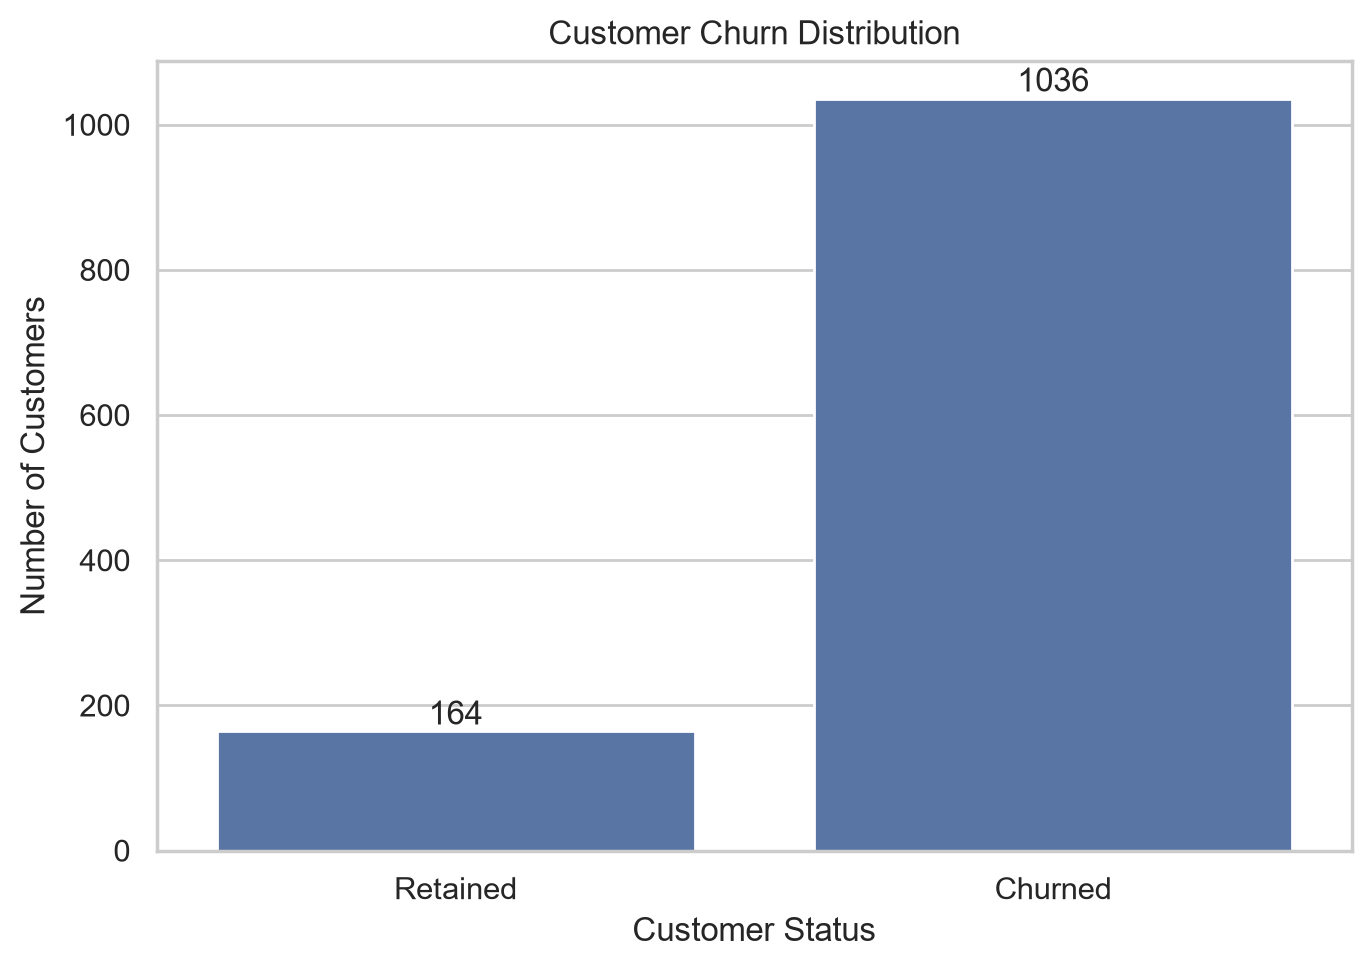


Figure: 02_contract_churn.png


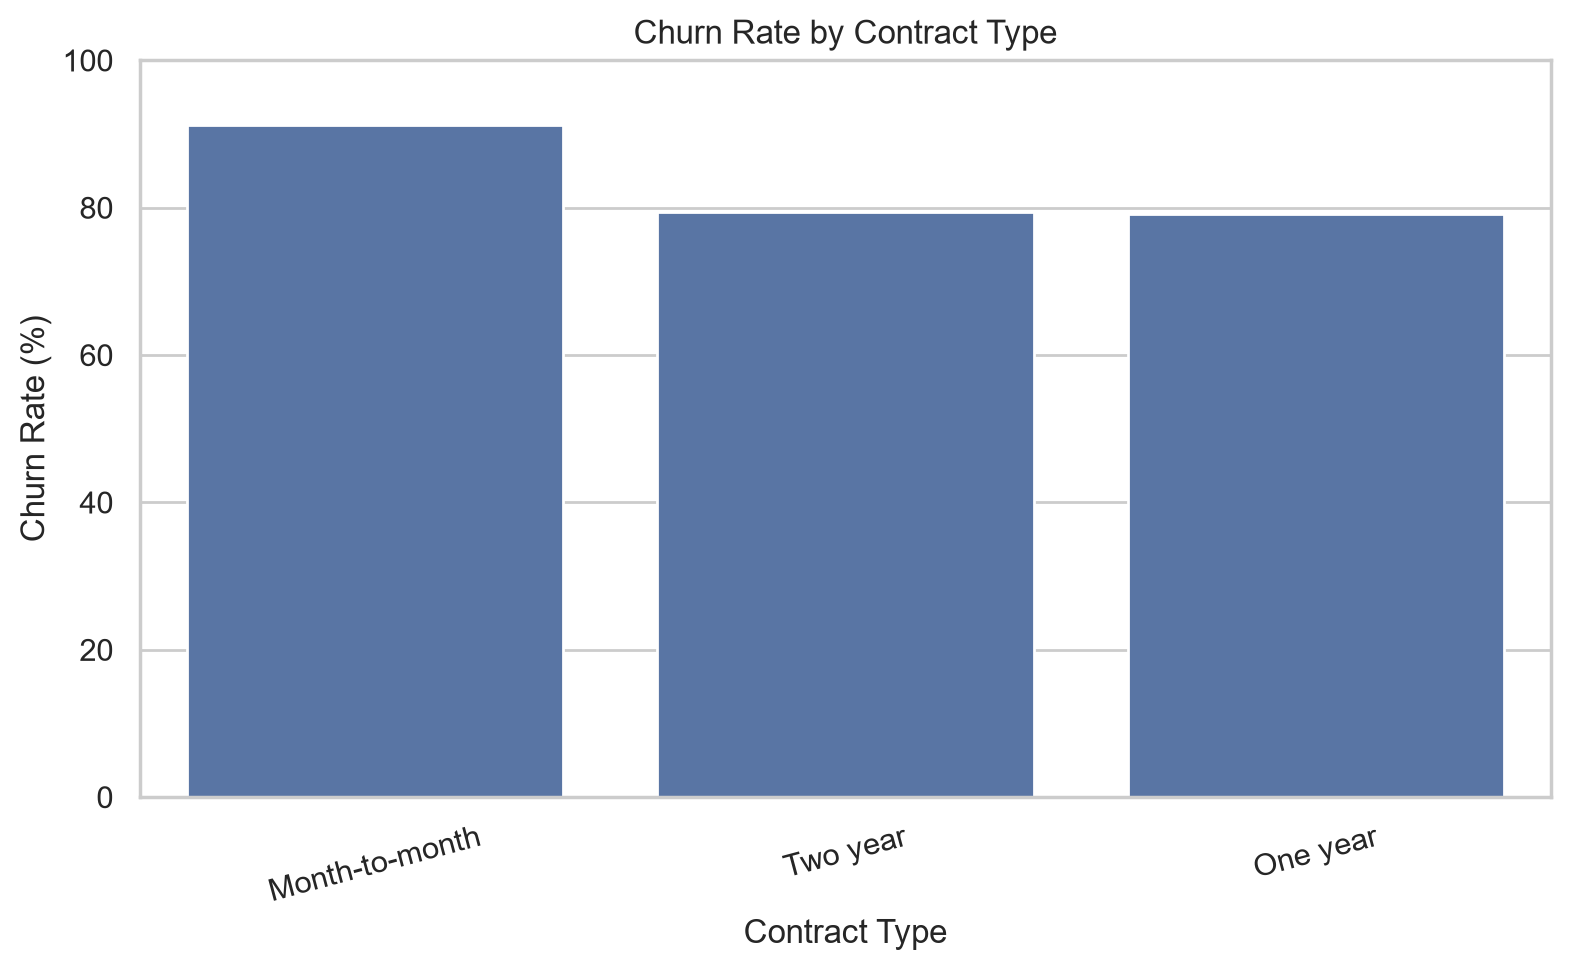


Figure: 03_tenure_churn.png


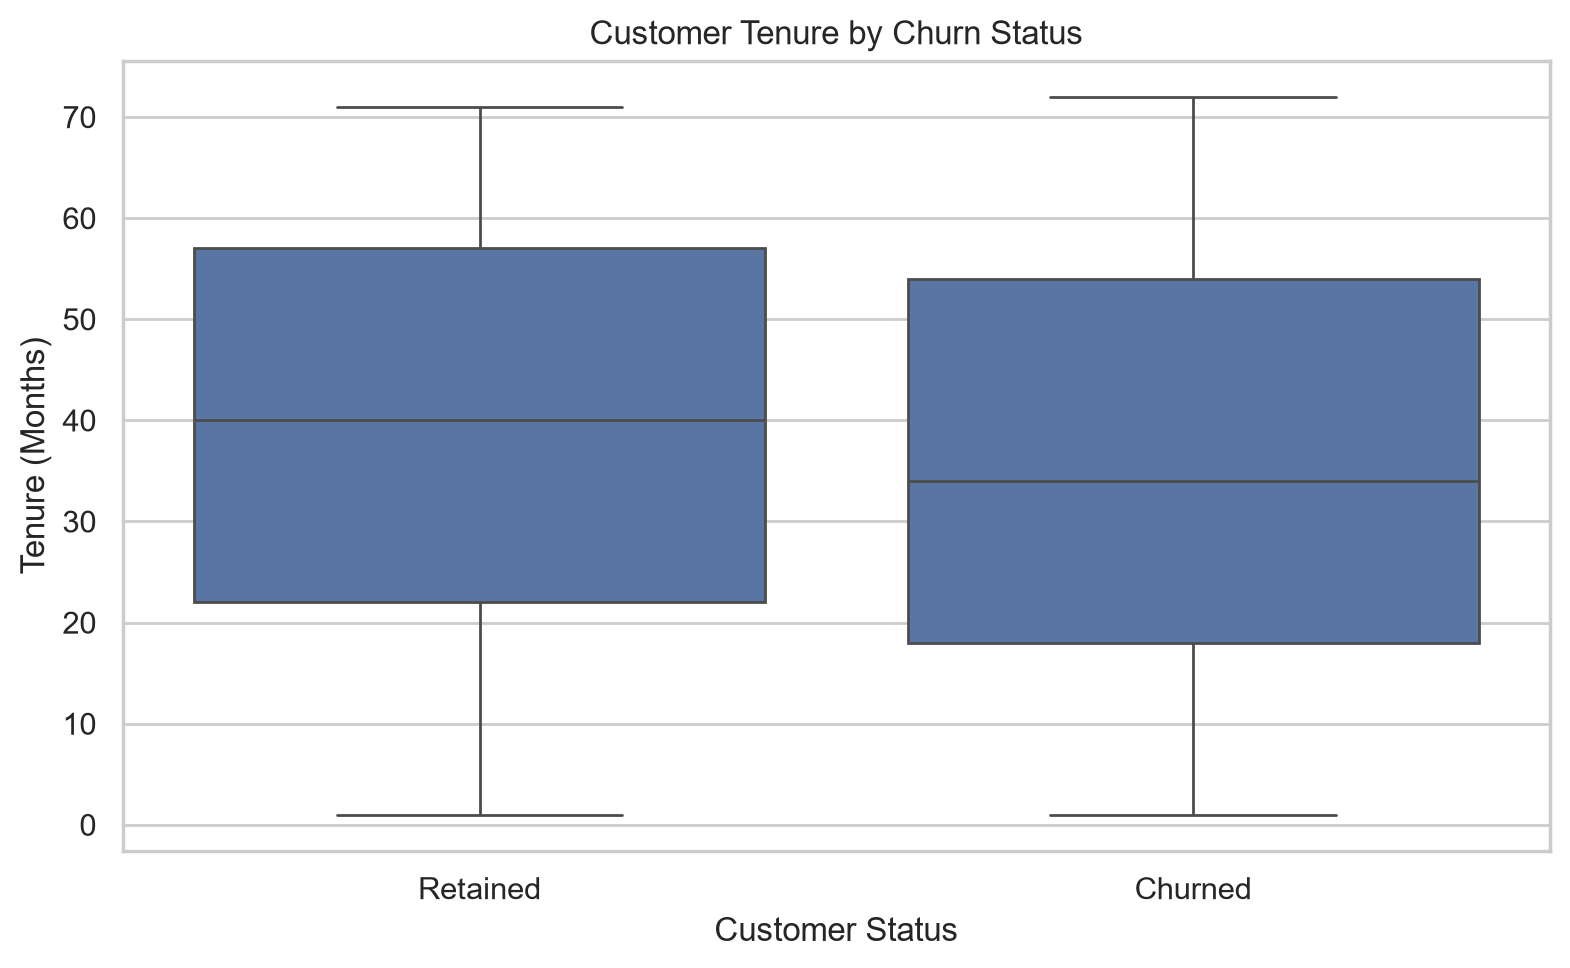


Figure: 04_monthly_charges.png


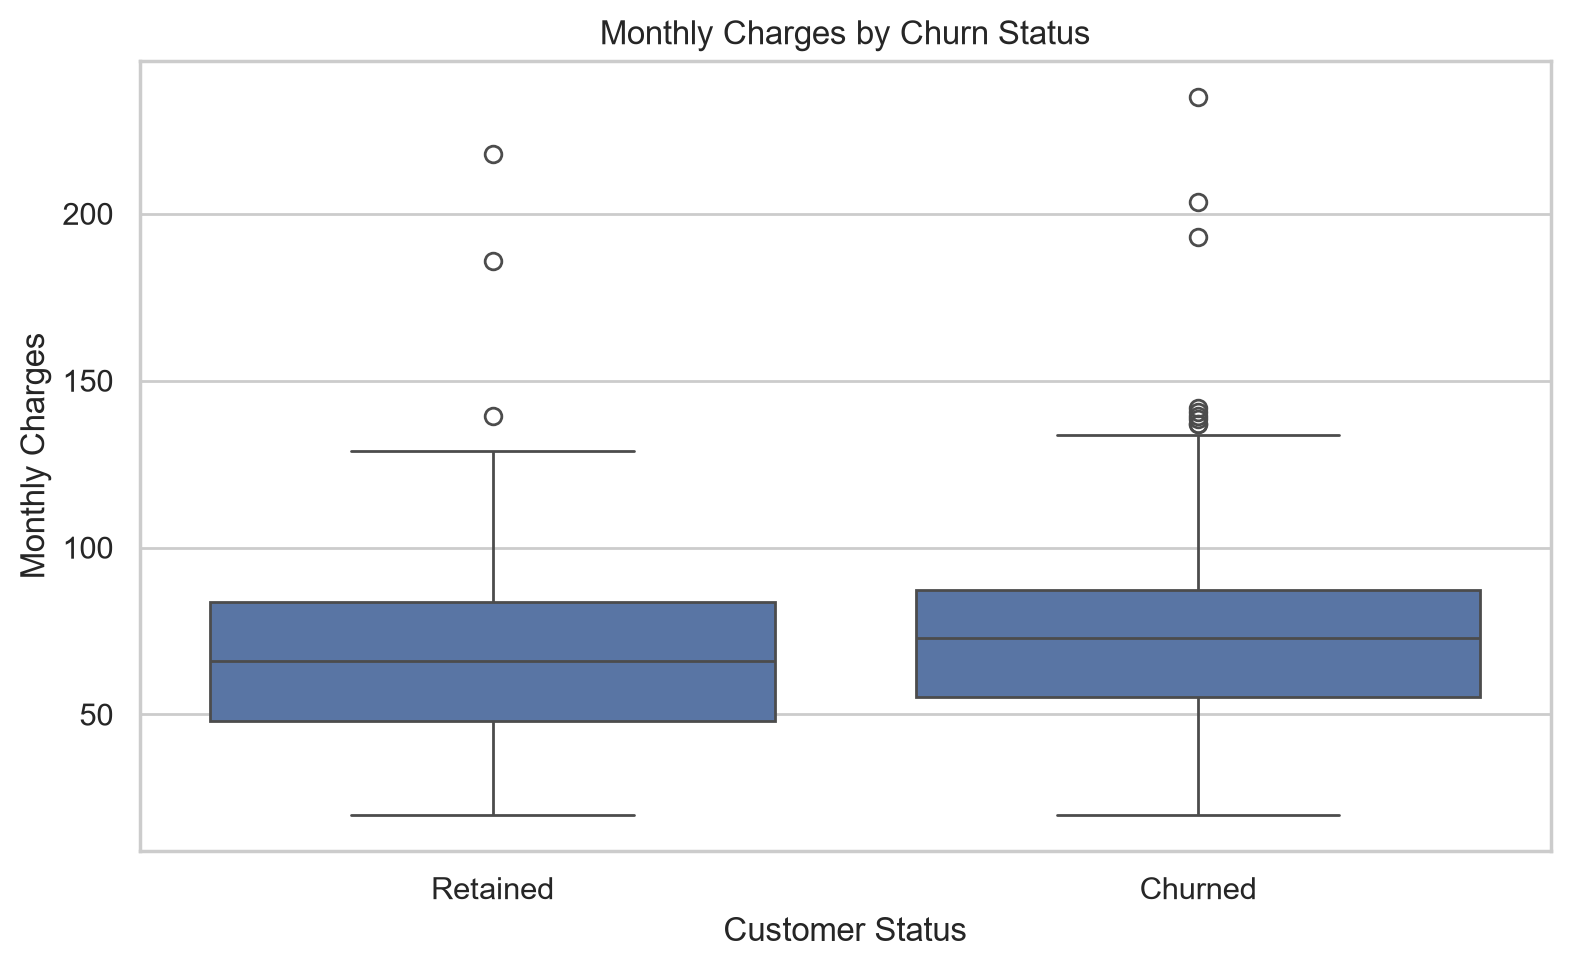


Figure: 05_satisfaction_complaints.png


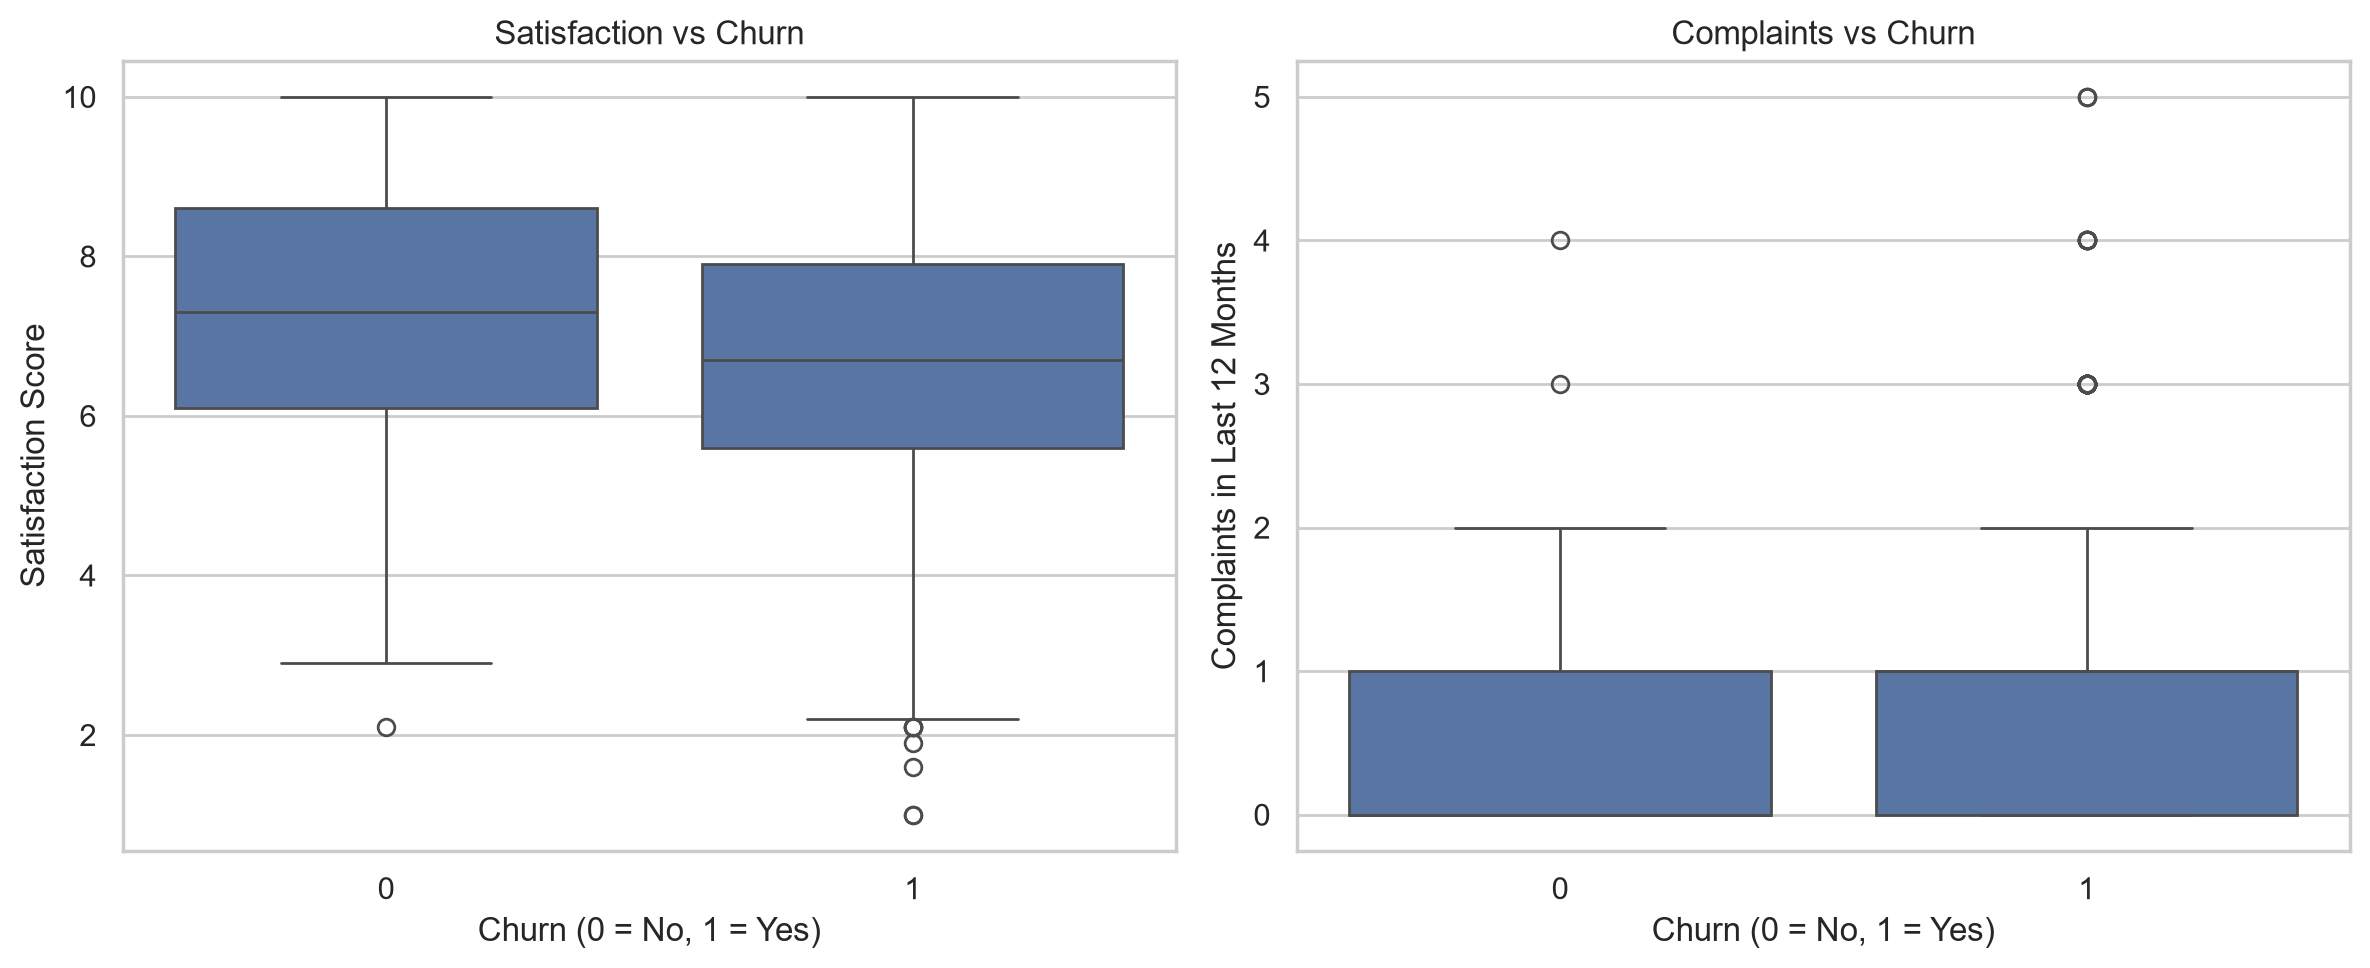


Figure: 06_late_payments.png


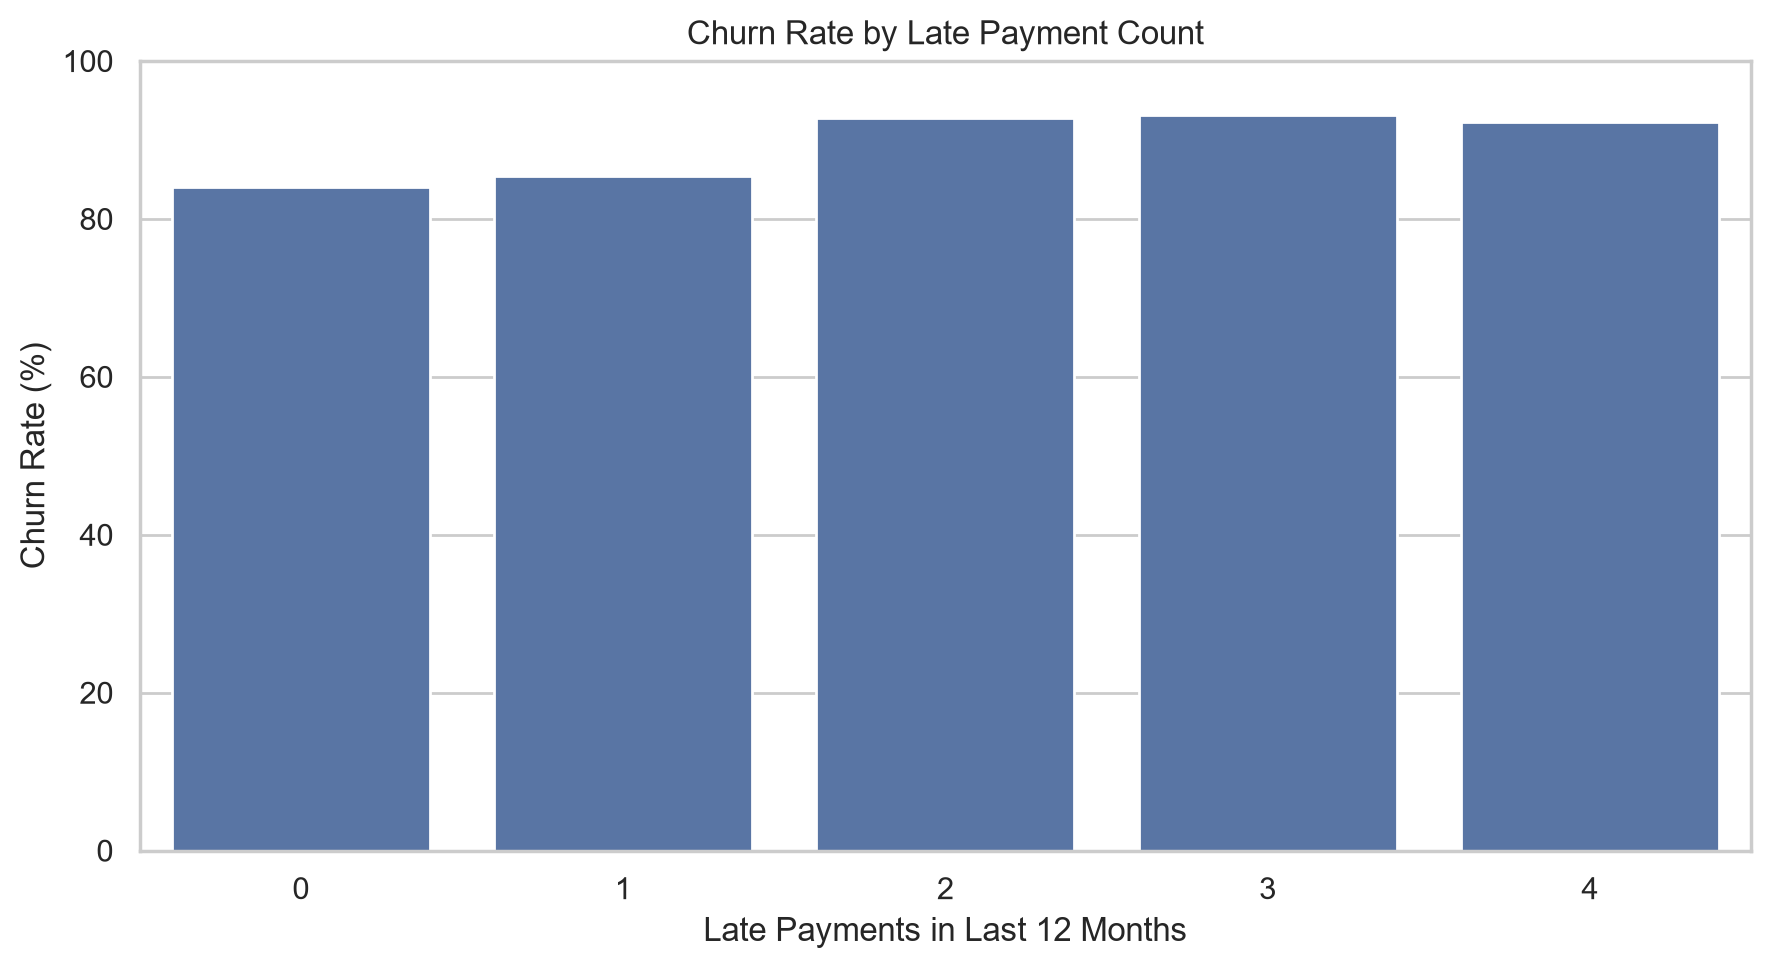


Figure: 07_monthly_usage.png


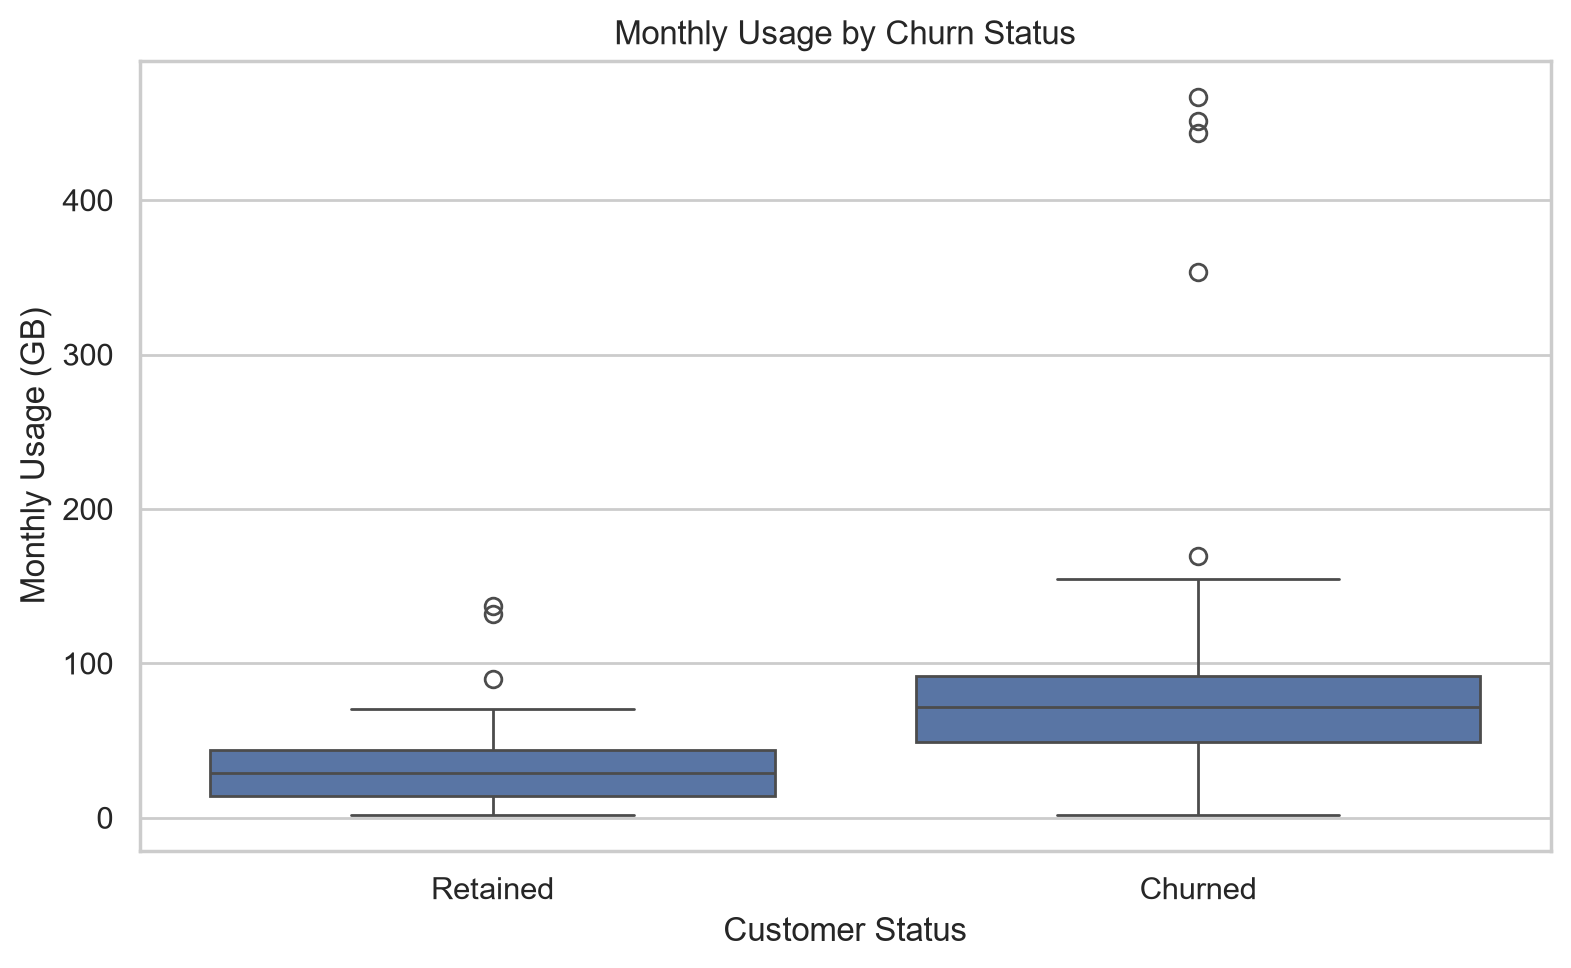


Figure: 08_correlation_heatmap.png


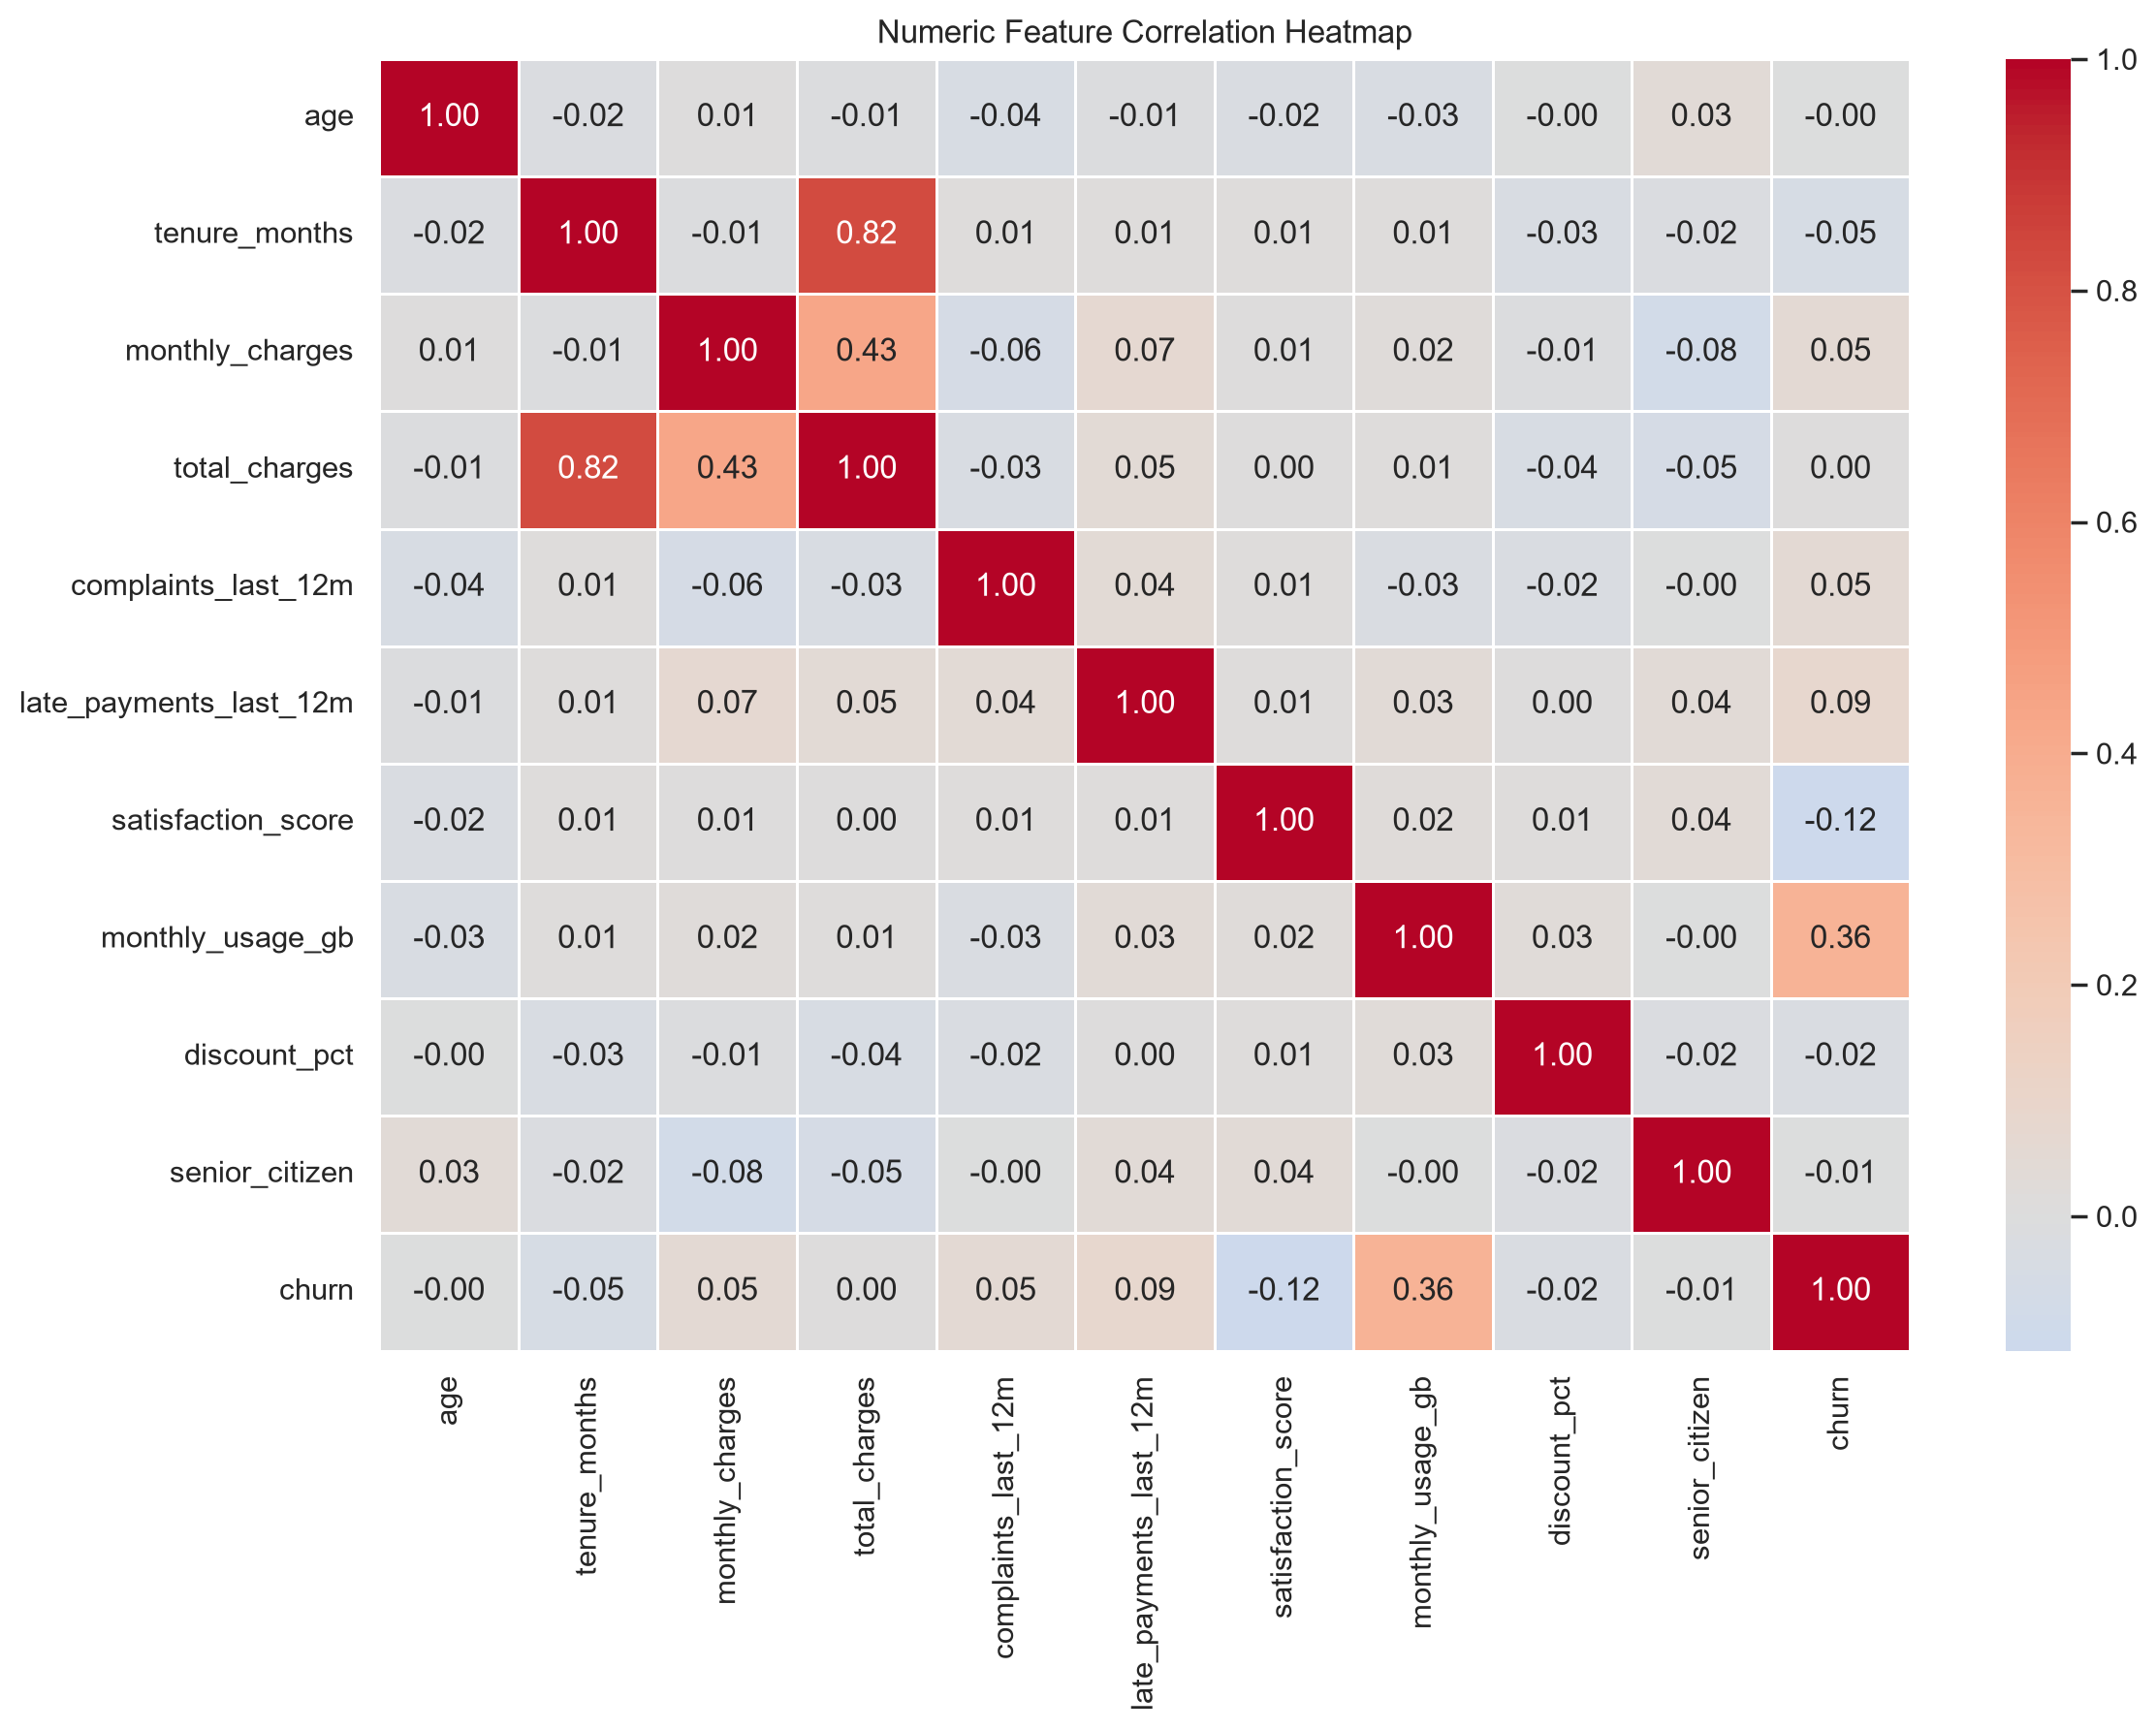

In [3]:
from src.eda import run_eda

run_eda()

FIGURE_DIR = ROOT / "reports" / "figures"

eda_figures = [
    "01_churn_distribution.png",
    "02_contract_churn.png",
    "03_tenure_churn.png",
    "04_monthly_charges.png",
    "05_satisfaction_complaints.png",
    "06_late_payments.png",
    "07_monthly_usage.png",
    "08_correlation_heatmap.png",
]

for filename in eda_figures:
    print("\nFigure:", filename)

    display(
        Image(
            filename=str(FIGURE_DIR / filename),
            width=750
        )
    )

### EDA Summary

The churn dataset is highly imbalanced, with most
customers belonging to the churn class.

Monthly usage, contract characteristics, billing
information and satisfaction measures are explored
as potential predictors.

The direction and strength of relationships must be
interpreted from the actual generated charts and
statistics rather than assumed in advance.

In [4]:
with open(
    ROOT / "reports" / "eda_summary.json",
    encoding="utf-8"
) as file:
    eda_summary = json.load(file)

print("Total customers:", eda_summary["total_customers"])

print(
    "Overall churn rate:",
    f"{eda_summary['overall_churn_rate']:.2%}"
)

print("\nMean feature values by churn class:")

display(
    pd.DataFrame(
        eda_summary["feature_means_by_churn"]
    )
)

Total customers: 1200
Overall churn rate: 86.33%

Mean feature values by churn class:


,0,1
tenure_months,38.780,35.868
monthly_charges,68.167,71.947
total_charges,2559.863,2569.308
satisfaction_score,7.262,6.661
complaints_last_12m,0.604,0.732
late_payments_last_12m,0.646,0.868
monthly_usage_gb,31.048,72.561


## 4. Feature Engineering

Five customer-level features are created.

| Feature | Purpose |
|---|---|
| Tenure years | Represent customer lifetime |
| Complaints per year | Measure complaint intensity |
| Late-payment risk | Identify repeated late payments |
| Charge-usage ratio | Represent charges relative to usage |
| Low-satisfaction flag | Identify dissatisfied customers |

Feature engineering is deterministic and uses only
predictor variables available at prediction time,
subject to the source-data timing assumptions.

It is implemented inside the modeling pipeline
to maintain consistent training and inference.

In [5]:
from src.feature_engineering import (
    ChurnFeatureEngineer,
    ENGINEERED_COLUMNS
)

X_sample = df.drop(
    columns=["customer_id", "churn"]
).head(10)

engineer = ChurnFeatureEngineer()

engineered_sample = engineer.fit_transform(X_sample)

print("Engineered features:")

display(
    engineered_sample[ENGINEERED_COLUMNS]
)

Engineered features:


,tenure_years,complaints_per_year,late_payment_risk,charge_usage_ratio,low_satisfaction_flag
0,5.333333,0.000000,0.0,2.779310,0.0
1,2.916667,0.342857,0.0,1.313043,0.0
2,5.916667,0.000000,0.0,NaN,0.0
3,4.583333,0.000000,0.0,1.620816,0.0
4,3.916667,0.765957,0.0,0.427824,0.0
5,5.500000,0.363636,1.0,NaN,0.0
6,3.166667,0.315789,1.0,NaN,0.0
7,4.333333,0.000000,0.0,0.307151,0.0
8,1.750000,0.571429,0.0,NaN,0.0
9,5.833333,0.342857,1.0,0.609772,0.0


## 5. Baseline Model Development

Three classification algorithms are trained:

1. Logistic Regression
2. Random Forest
3. Gradient Boosting

### Data Splitting

The dataset is divided using stratified sampling:

- 80% training
- 20% testing

The final test partition is reserved during
model selection.

### Baseline Evaluation

Five-fold stratified cross-validation is used
to estimate model performance on training data.

Evaluation metrics include precision, recall,
F1-score, ROC-AUC and PR-AUC.

PR-AUC is emphasized because customer churn is
highly imbalanced.

In [6]:
from src.modeling import main as baseline_main

baseline_main()

BASELINE_PATH = (
    ROOT / "reports" / "baseline_model_comparison.csv"
)

baseline_results = pd.read_csv(BASELINE_PATH)

print("Baseline model comparison:")

display(
    baseline_results.sort_values(
        "pr_auc_mean",
        ascending=False
    )
)

CUSTOMER CHURN — BASELINE MODEL COMPARISON
Training records: 960
Reserved test records: 240
Training churn rate: 86.35%

Evaluating: Logistic Regression


PR-AUC: 0.9722
ROC-AUC: 0.8694
F1: 0.9345
Precision: 0.9071
Recall: 0.9638

Evaluating: Random Forest


PR-AUC: 0.9693
ROC-AUC: 0.8538
F1: 0.9312
Precision: 0.8816
Recall: 0.9867

Evaluating: Gradient Boosting


PR-AUC: 0.9719
ROC-AUC: 0.8704
F1: 0.9317
Precision: 0.9029
Recall: 0.9626

BASELINE MODEL COMPARISON
              model  pr_auc_mean  pr_auc_std  roc_auc_mean  roc_auc_std  f1_mean  f1_std  precision_mean  precision_std  recall_mean  recall_std
Logistic Regression       0.9722      0.0148        0.8694       0.0465   0.9345  0.0106          0.9071         0.0127       0.9638      0.0157
  Gradient Boosting       0.9719      0.0080        0.8704       0.0210   0.9317  0.0090          0.9029         0.0142       0.9626      0.0117
      Random Forest       0.9693      0.0088        0.8538       0.0271   0.9312  0.0084          0.8816         0.0124       0.9867      0.0045

Saved: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\reports\baseline_model_comparison.csv

Milestone 4 execution completed.
Baseline model comparison:


,model,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std
0,Logistic Regression,0.9722,0.0148,0.8694,0.0465,0.9345,0.0106,0.9071,0.0127,0.9638,0.0157
1,Gradient Boosting,0.9719,0.0080,0.8704,0.0210,0.9317,0.0090,0.9029,0.0142,0.9626,0.0117
2,Random Forest,0.9693,0.0088,0.8538,0.0271,0.9312,0.0084,0.8816,0.0124,0.9867,0.0045


## 6. Hyperparameter Optimization

RandomizedSearchCV is used with five-fold
stratified cross-validation.

Eight hyperparameter combinations are evaluated
for each classification algorithm.

The search uses Average Precision (PR-AUC)
as the primary selection metric.

Additional diagnostics:

- ROC-AUC
- Precision among the highest-risk 20%
- Recall among the highest-risk 20%
- Lift at 20%

The selected cross-validation scores are not
independent nested-CV estimates because
hyperparameters were selected on the same
training partition.

In [7]:
from src.hyperparameter_tuning import main as tuning_main

tuning_main()

TUNING_PATH = (
    ROOT
    / "reports"
    / "hyperparameter_tuning_results.csv"
)

tuning_results = pd.read_csv(TUNING_PATH)

print("Tuned model comparison:")

display(
    tuning_results.sort_values(
        "search_best_pr_auc",
        ascending=False
    )
)

HYPERPARAMETER TUNING — CUSTOMER CHURN
Training records: 960
Reserved test records: 240
Cross-validation folds: 5
Random search iterations per model: 8

Tuning Logistic Regression...


Best search PR-AUC: 0.9726
Selected CV ROC-AUC: 0.8718
Selected CV top-20% recall: 0.2316
Selected CV top-20% lift: 1.1402
Best parameters: {'classifier__solver': 'liblinear', 'classifier__class_weight': None, 'classifier__C': 0.1}

Tuning Random Forest...


Best search PR-AUC: 0.9739
Selected CV ROC-AUC: 0.8703
Selected CV top-20% recall: 0.2328
Selected CV top-20% lift: 1.1462
Best parameters: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_depth': 10, 'classifier__class_weight': 'balanced'}

Tuning Gradient Boosting...


Best search PR-AUC: 0.9782
Selected CV ROC-AUC: 0.8796
Selected CV top-20% recall: 0.2340
Selected CV top-20% lift: 1.1521
Best parameters: {'classifier__subsample': 0.8, 'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 5, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.01}

TUNED MODEL COMPARISON
              model  search_best_pr_auc  roc_auc_mean  top20_precision_mean  top20_recall_mean  top20_lift_mean
  Gradient Boosting              0.9782        0.8796                0.9949             0.2340           1.1521
      Random Forest              0.9739        0.8703                0.9897             0.2328           1.1462
Logistic Regression              0.9726        0.8718                0.9846             0.2316           1.1402

Saved: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\reports\hyperparameter_tuning_results.csv
Saved: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-e

,model,search_best_pr_auc,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,top20_precision_mean,top20_precision_std,top20_recall_mean,top20_recall_std,top20_lift_mean,top20_lift_std
0,Gradient Boosting,0.978155,0.978155,0.005101,0.879605,0.018065,0.994872,0.010256,0.234020,0.002611,1.152097,0.012854
1,Random Forest,0.973870,0.973870,0.007465,0.870326,0.017440,0.989744,0.012561,0.232815,0.003226,1.146166,0.015881
2,Logistic Regression,0.972598,0.972598,0.015609,0.871752,0.049553,0.984615,0.020513,0.231610,0.005060,1.140234,0.024913


## 7. Class Imbalance and Model Evaluation

### Class Imbalance

The training dataset contains a high proportion
of customers labeled as churners.

Stratified cross-validation preserves approximately
the same target distribution in each fold.

Class-weight configurations were explored during
hyperparameter tuning.

No synthetic resampling is applied to the final
selected Gradient Boosting model.

### Final Model

The selected model is Gradient Boosting.

An operating threshold is selected using training
out-of-fold predictions and an explicit precision
requirement.

The threshold is distinct from the top-20%
contact-budget policy.

### Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC
- Brier score
- Confusion matrix

Probability calibration and fold-to-fold
robustness are also examined.

The final test set is evaluated only after
model selection and threshold selection
have been finalized.

In [8]:
from src.evaluation import main as evaluation_main

evaluation_main()

METRICS_PATH = (
    ROOT / "reports" / "final_evaluation_metrics.json"
)

with open(METRICS_PATH, encoding="utf-8") as file:
    evaluation_results = json.load(file)

print("Selected model:", evaluation_results["model_name"])

print(
    "Selected threshold:",
    evaluation_results["selected_threshold"]
)

print("\nFinal test performance:")

test_metrics = evaluation_results["test_metrics"]

metric_names = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc",
    "brier_score",
]

display(
    pd.DataFrame(
        {
            "Metric": metric_names,
            "Value": [
                test_metrics[name]
                for name in metric_names
            ],
        }
    )
)

print("\nConfusion matrix:")
display(
    pd.DataFrame(
        test_metrics["confusion_matrix"],
        index=["Actual Retained", "Actual Churned"],
        columns=["Predicted Retained", "Predicted Churned"],
    )
)

CUSTOMER CHURN — FINAL MODEL EVALUATION
Training size: 960
Reserved test size: 240
Training churn prevalence: 0.8635

Generating training out-of-fold predictions...


Selected threshold: 0.67



Training OOF performance:
PR-AUC: 0.9749
ROC-AUC: 0.8742
F1: 0.9284

Fitting selected model on full training set...


Evaluating reserved test set...

FINAL TEST RESULTS
accuracy: 0.8750
precision: 0.8933
recall: 0.9710
f1: 0.9306
roc_auc: 0.8923
pr_auc: 0.9808
brier_score: 0.0902



Saved final model: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\models\03_model_artifact.joblib
Saved metrics: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\reports\final_evaluation_metrics.json
Saved test predictions: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\reports\test_predictions.csv

Milestone 6 evaluation completed.
Selected model: Gradient Boosting
Selected threshold: 0.67

Final test performance:


,Metric,Value
0,accuracy,0.875000
1,precision,0.893333
2,recall,0.971014
3,f1,0.930556
4,roc_auc,0.892329
5,pr_auc,0.980823
6,brier_score,0.090241



Confusion matrix:


,Predicted Retained,Predicted Churned
Actual Retained,9,24
Actual Churned,6,201



Figure: 09_threshold_analysis.png


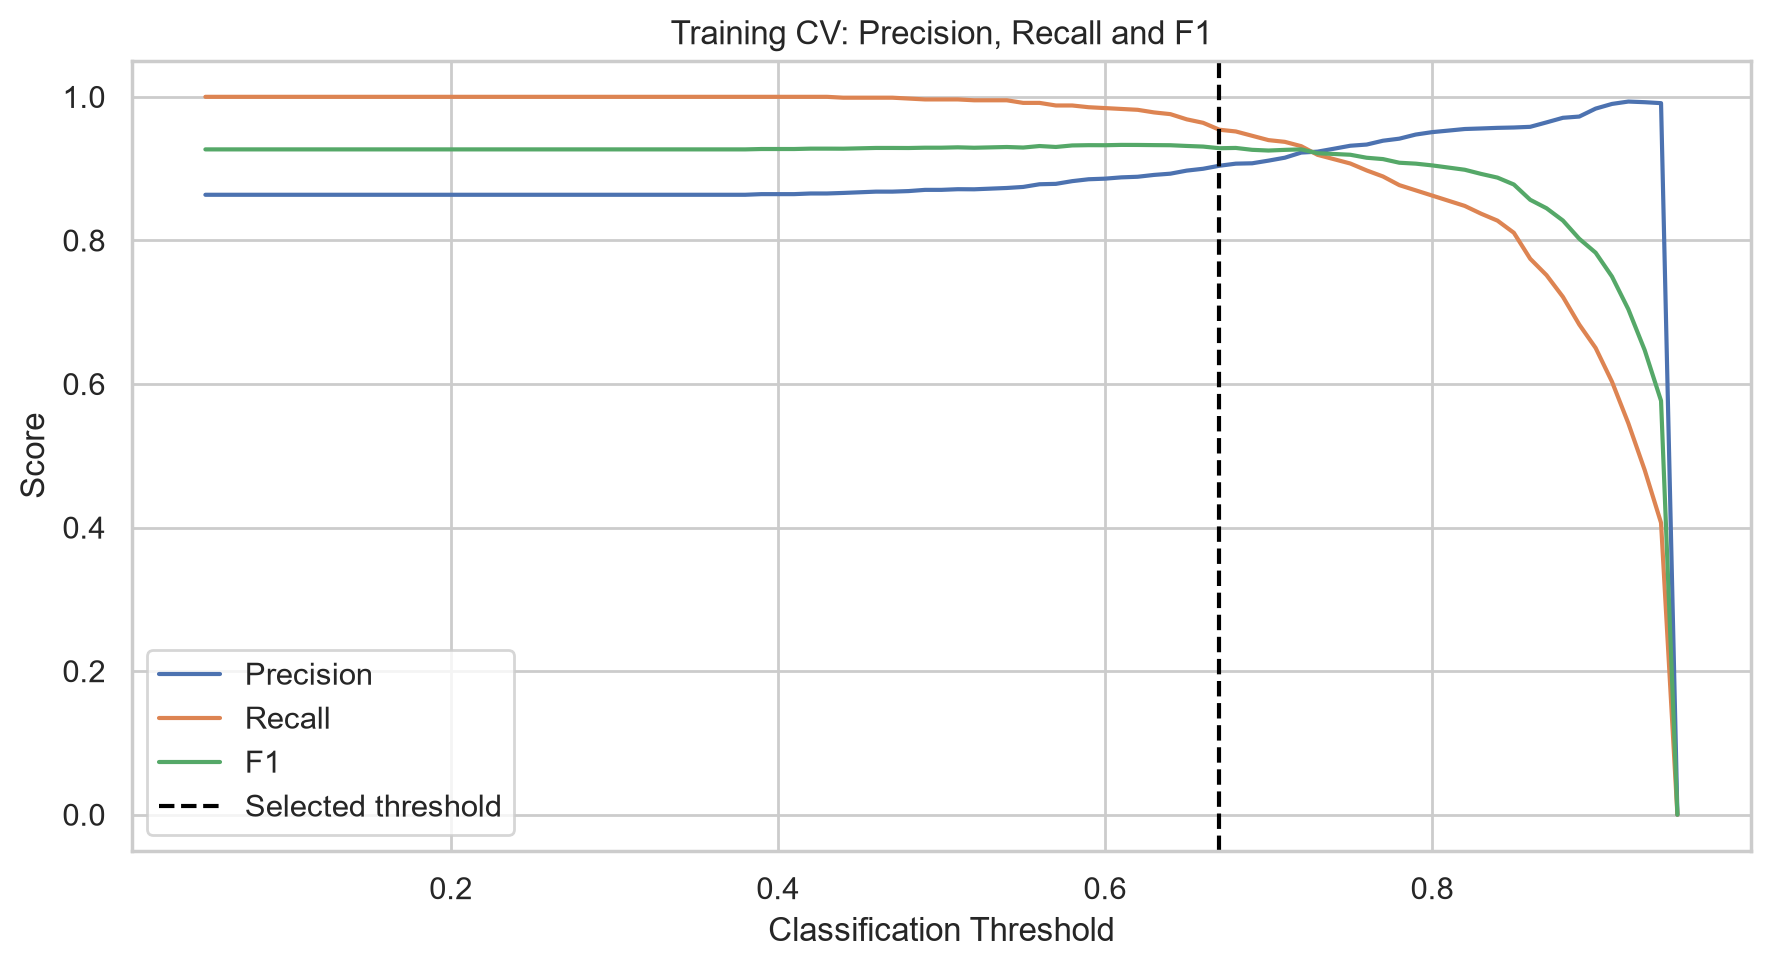


Figure: 10_calibration_curve.png


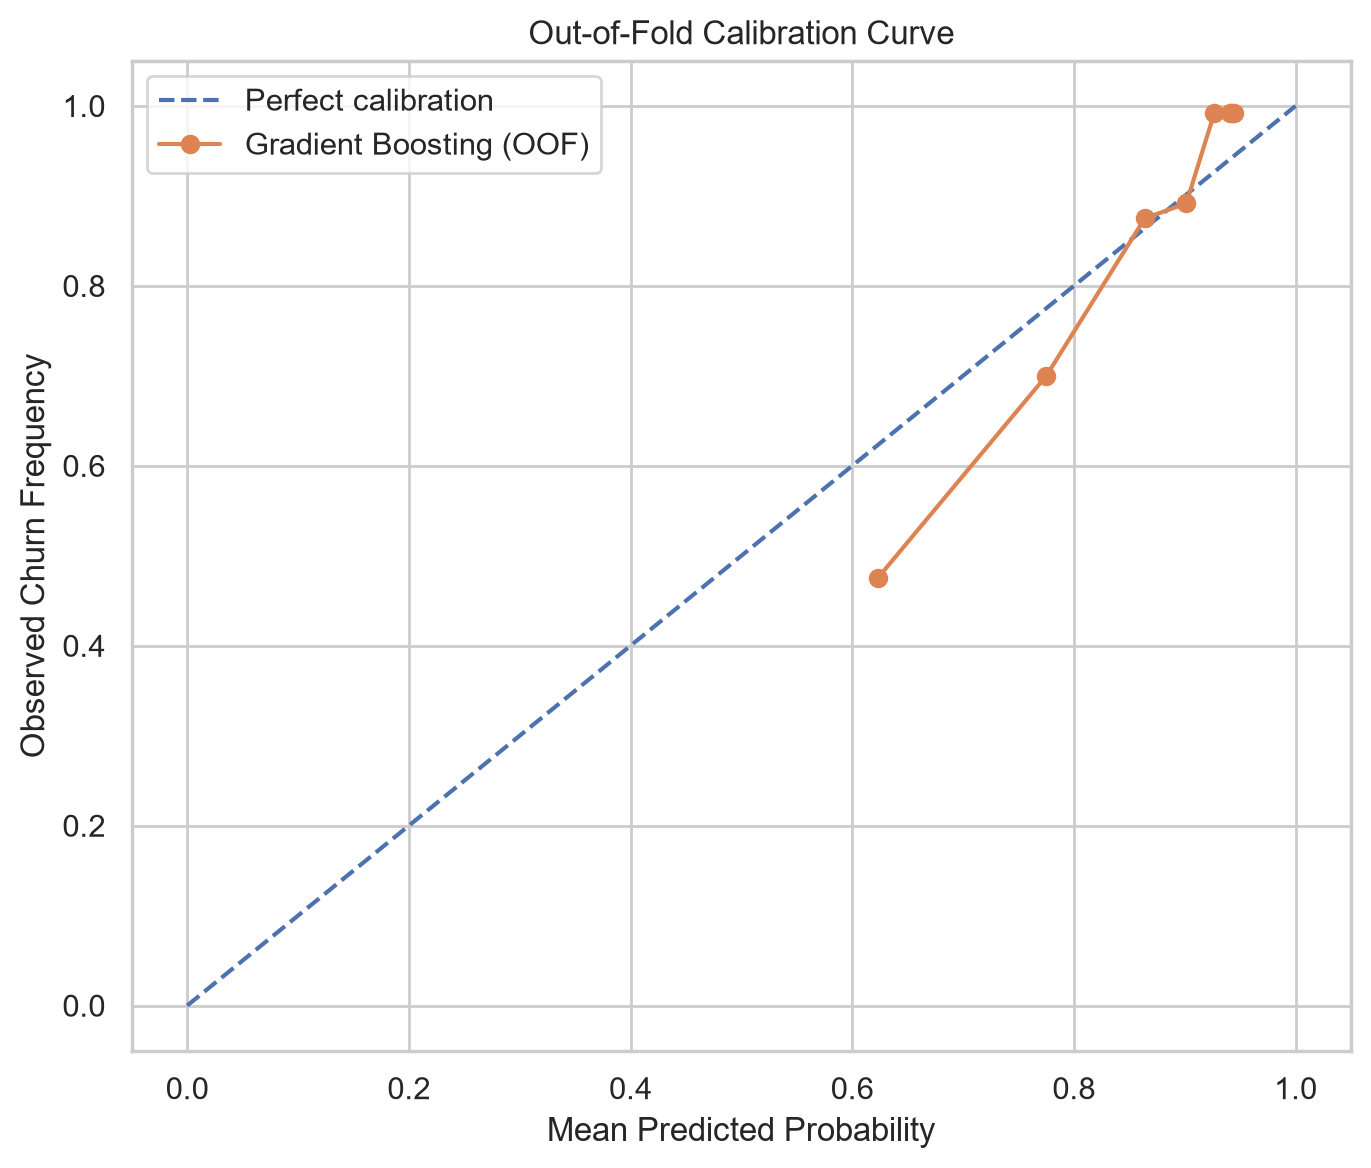


Figure: 11_test_roc_curve.png


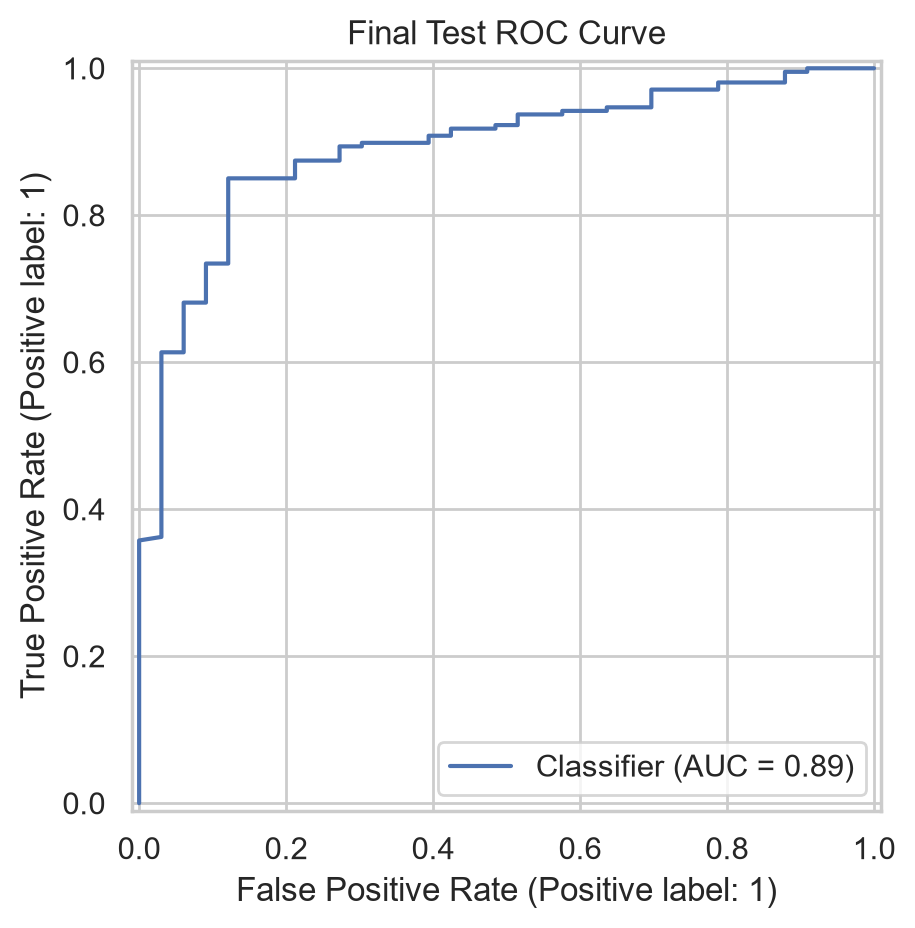


Figure: 12_test_precision_recall.png


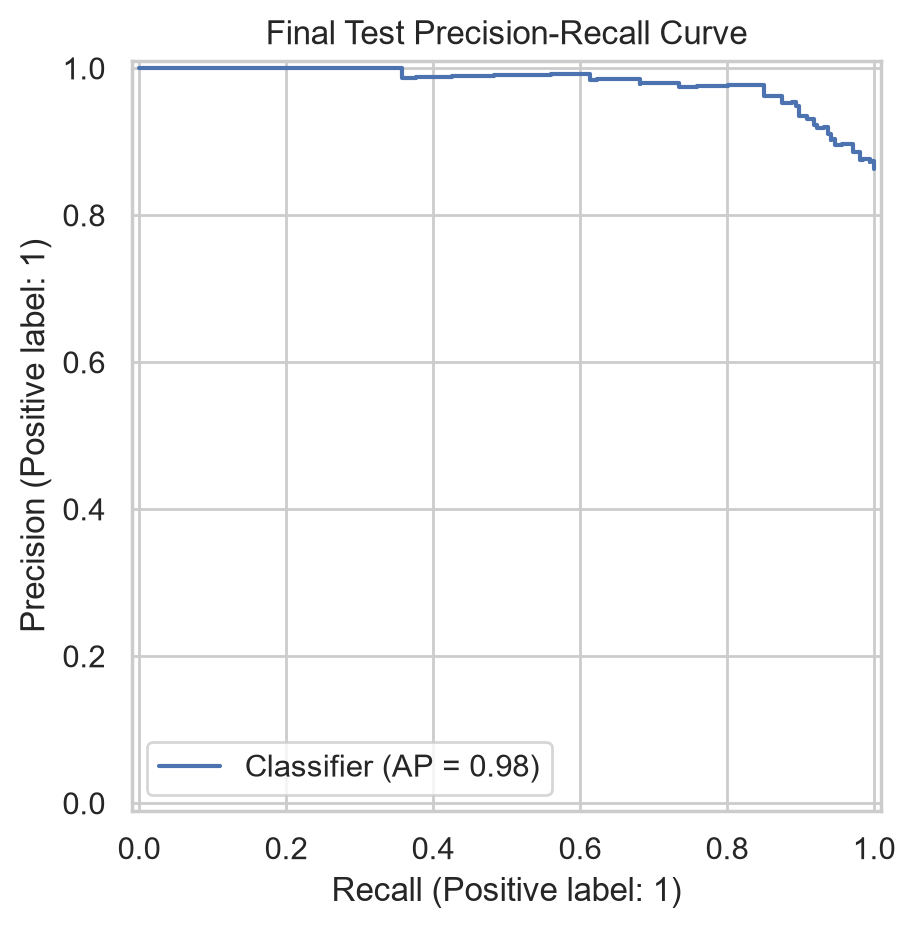


Figure: 13_test_confusion_matrix.png


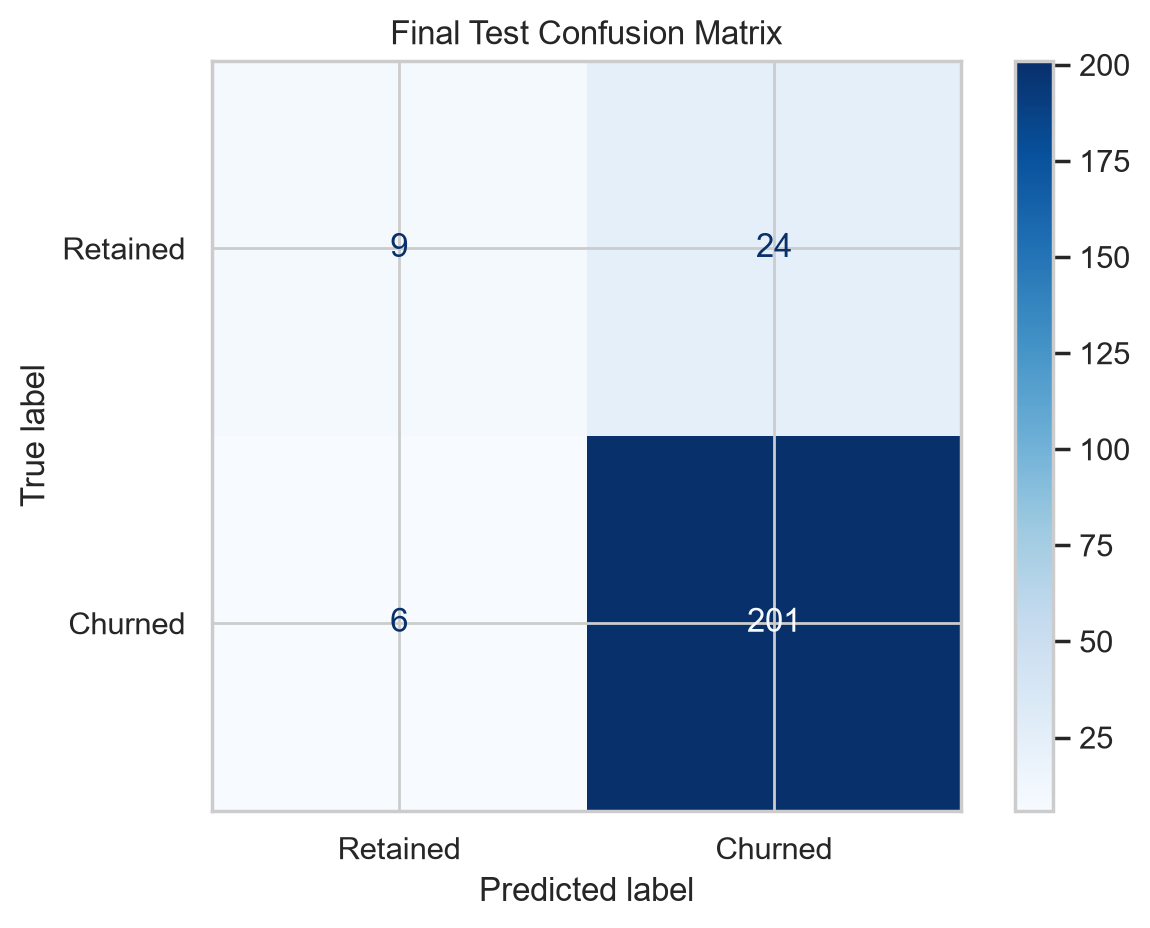

In [9]:
evaluation_figures = [
    "09_threshold_analysis.png",
    "10_calibration_curve.png",
    "11_test_roc_curve.png",
    "12_test_precision_recall.png",
    "13_test_confusion_matrix.png",
]

for filename in evaluation_figures:
    print("\nFigure:", filename)

    display(
        Image(
            filename=str(FIGURE_DIR / filename),
            width=750
        )
    )

## 8. Explainable Machine Learning

Explainability helps identify which predictor
variables influence model outputs.

### Global Explanation

Permutation importance measures the decrease
in model performance when individual features
are shuffled.

### Individual Explanations

Three customers are selected:

1. Relatively low-risk customer
2. Relatively medium-risk customer
3. Relatively high-risk customer

Individual predictions are investigated using
one-feature-at-a-time reference replacement.

These explanations measure model sensitivity.

They are not SHAP values and do not establish
causal relationships between customer behavior
and churn.

In [10]:
from src.explainability import main as explainability_main

explainability_main()

IMPORTANCE_PATH = (
    ROOT / "reports" / "global_feature_importance.csv"
)

importance = pd.read_csv(IMPORTANCE_PATH)

print("Global feature importance:")

display(importance.head(15))

with open(
    ROOT / "reports" / "customer_explanations.json",
    encoding="utf-8"
) as file:
    explanations = json.load(file)

print("\nIndividual customer explanations:")

for category, customer in explanations["customers"].items():
    print(
        category,
        "| Customer:",
        customer["customer_id"],
        "| Predicted probability:",
        f"{customer['predicted_churn_probability']:.2%}"
    )

MODEL EXPLAINABILITY ANALYSIS
Model: Gradient Boosting

Calculating permutation importance...



Top global features:
               feature  importance_mean  importance_std
      monthly_usage_gb         0.101627        0.012860
       monthly_charges         0.006200        0.003571
         contract_type         0.004681        0.002364
    satisfaction_score         0.002868        0.000998
      internet_service         0.000641        0.000372
late_payments_last_12m         0.000252        0.000149
         total_charges         0.000029        0.000040
        senior_citizen         0.000018        0.000104
          discount_pct         0.000007        0.000216
            dependents         0.000000        0.000000

Explaining individual customer predictions...

LOW_RISK
Customer ID: CUST101087
Churn probability: 0.4869
Actual churn: 0
Top sensitivity factors:
  monthly_usage_gb: -0.3645
  satisfaction_score: -0.0926
  tenure_months: -0.0714
  complaints_last_12m: +0.0448
  contract_type: -0.0368



MEDIUM_RISK
Customer ID: CUST101050
Churn probability: 0.9185
Actual churn: 1
Top sensitivity factors:
  monthly_usage_gb: +0.0024
  satisfaction_score: +0.0009
  age: +0.0000
  tenure_months: +0.0000
  contract_type: +0.0000



HIGH_RISK
Customer ID: CUST100035
Churn probability: 0.9450
Actual churn: 1
Top sensitivity factors:
  monthly_usage_gb: +0.0281
  tenure_months: +0.0006
  age: +0.0000
  contract_type: +0.0000
  internet_service: +0.0000



Saved: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\reports\global_feature_importance.csv
Saved: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\reports\customer_explanations.json

Explainability analysis completed.
Global feature importance:


,feature,importance_mean,importance_std
0,monthly_usage_gb,0.101627,0.012860
1,monthly_charges,0.006200,0.003571
2,contract_type,0.004681,0.002364
3,satisfaction_score,0.002868,0.000998
4,internet_service,0.000641,0.000372
5,late_payments_last_12m,0.000252,0.000149
6,total_charges,0.000029,0.000040
7,senior_citizen,0.000018,0.000104
8,discount_pct,0.000007,0.000216
9,dependents,0.000000,0.000000



Individual customer explanations:
low_risk | Customer: CUST101087 | Predicted probability: 48.69%
medium_risk | Customer: CUST101050 | Predicted probability: 91.85%
high_risk | Customer: CUST100035 | Predicted probability: 94.50%



Figure: 14_global_feature_importance.png


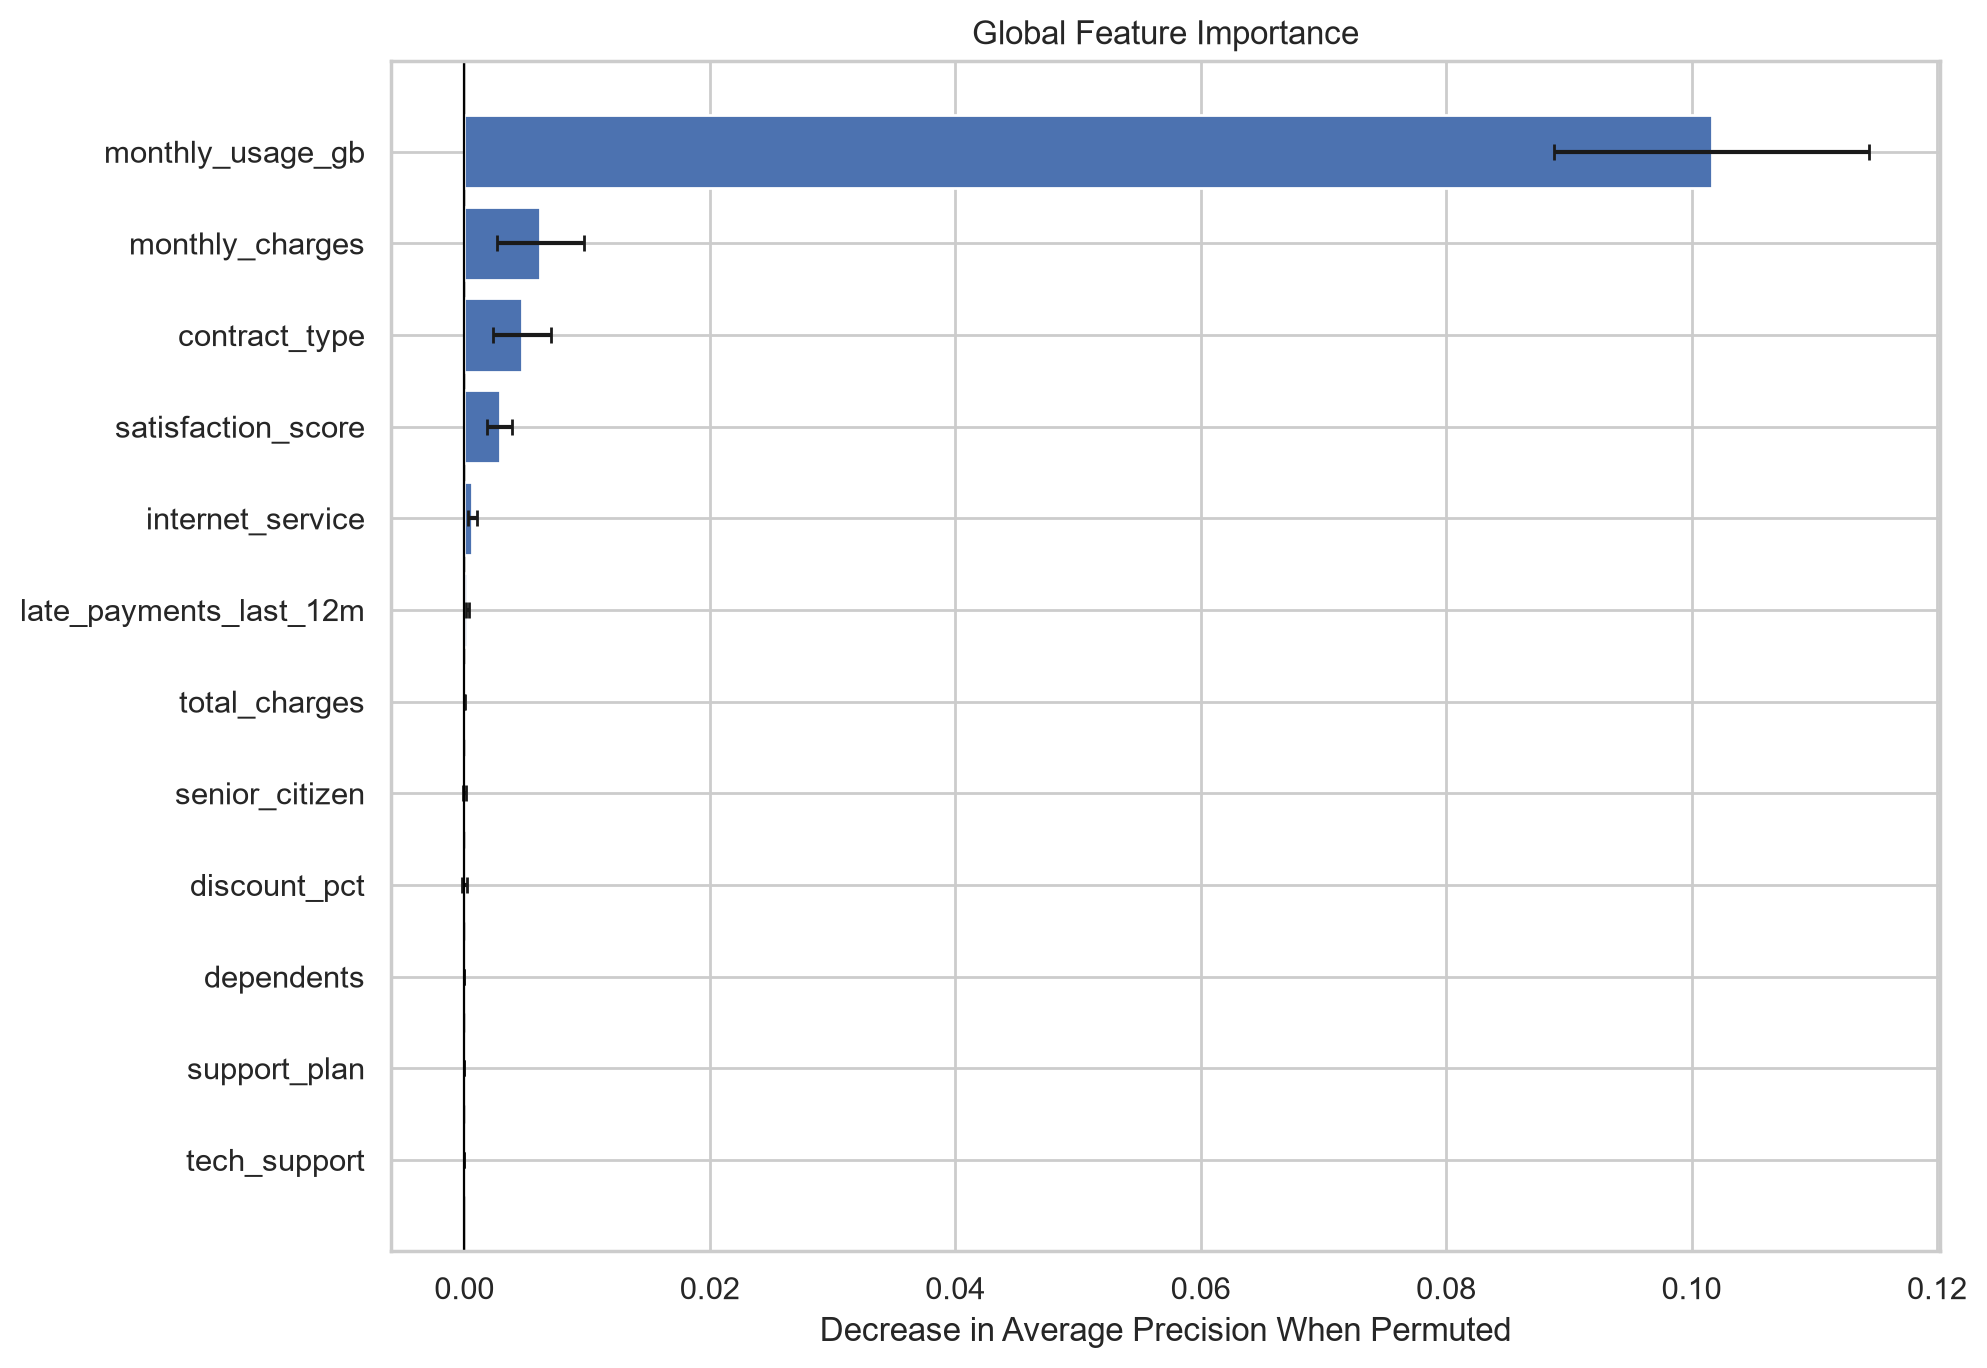


Figure: 15_low_risk_explanation.png


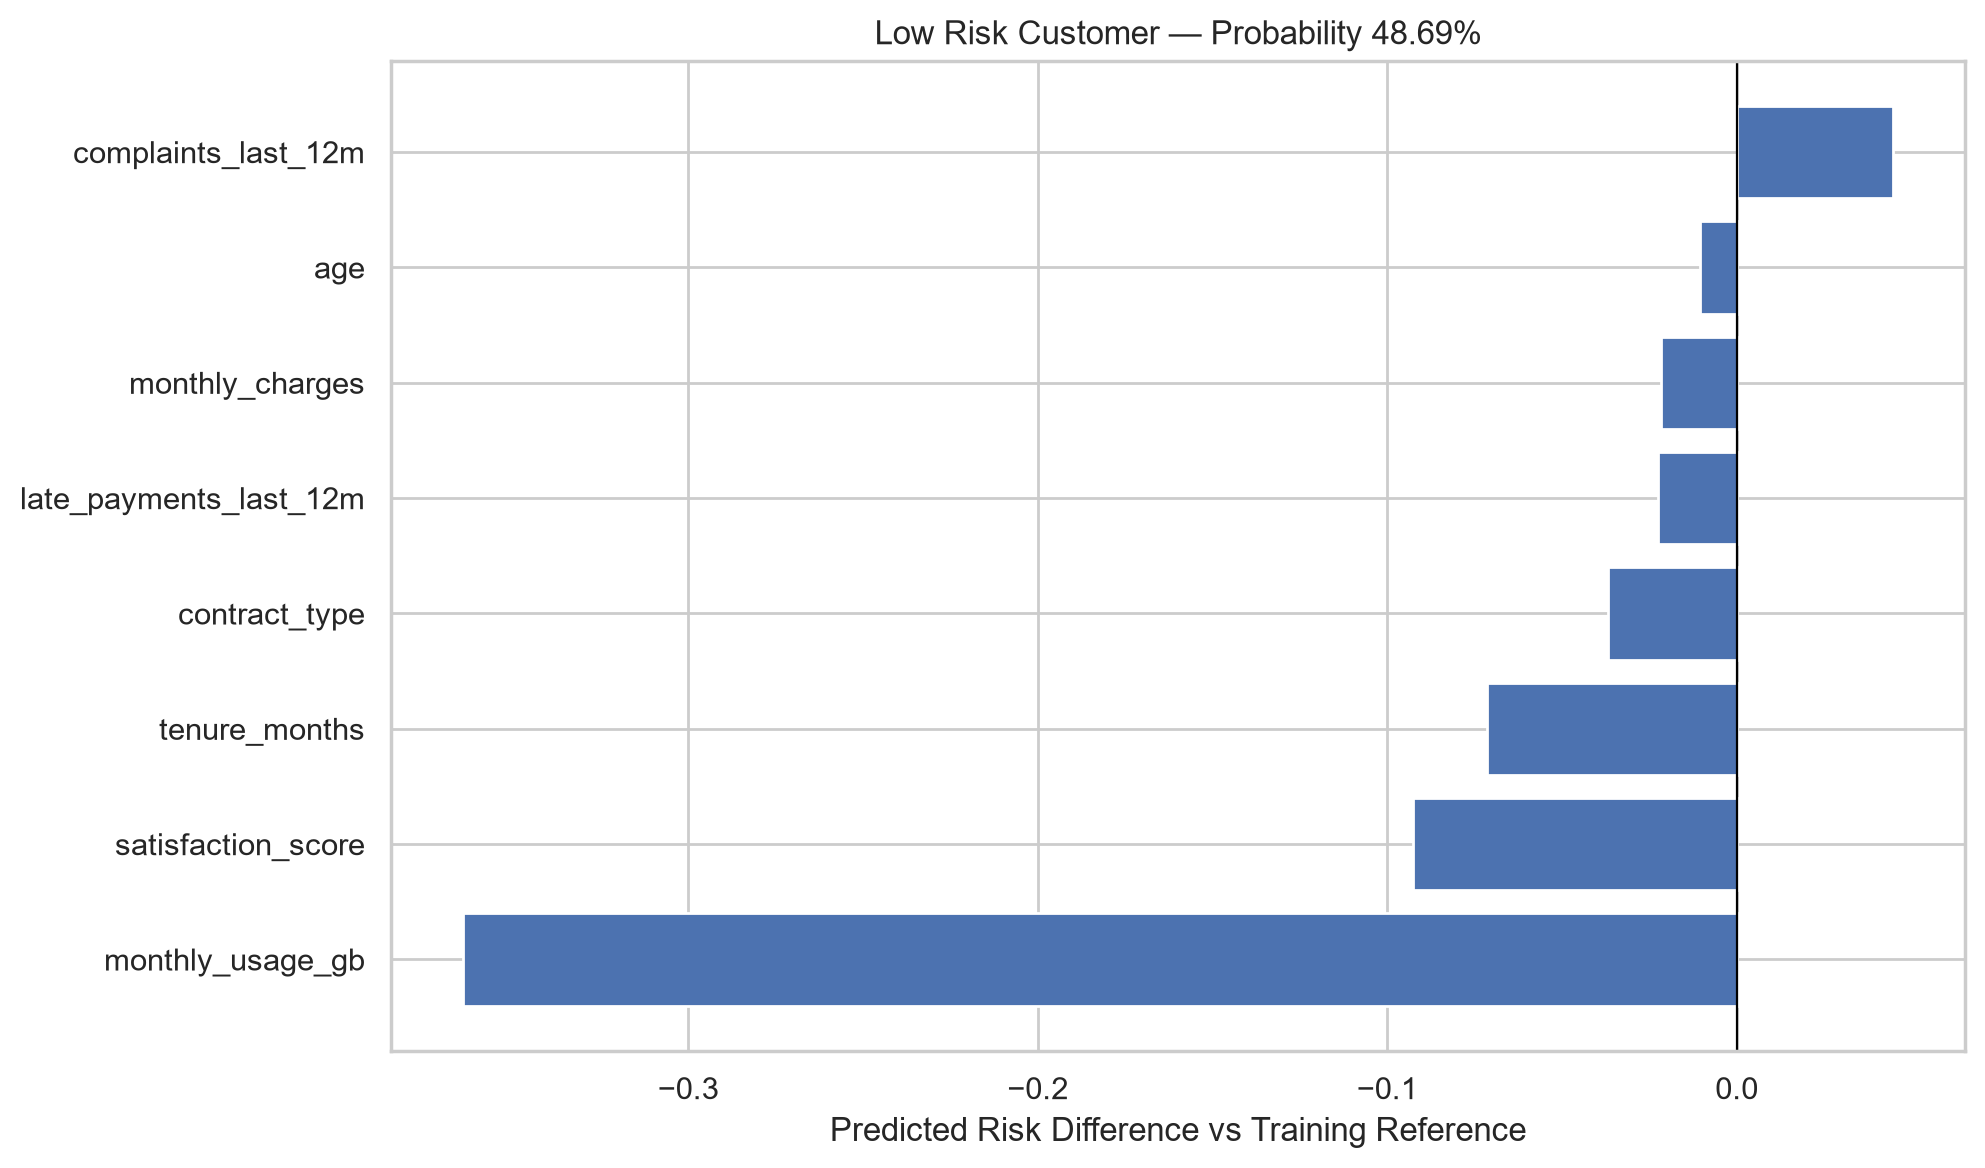


Figure: 15_medium_risk_explanation.png


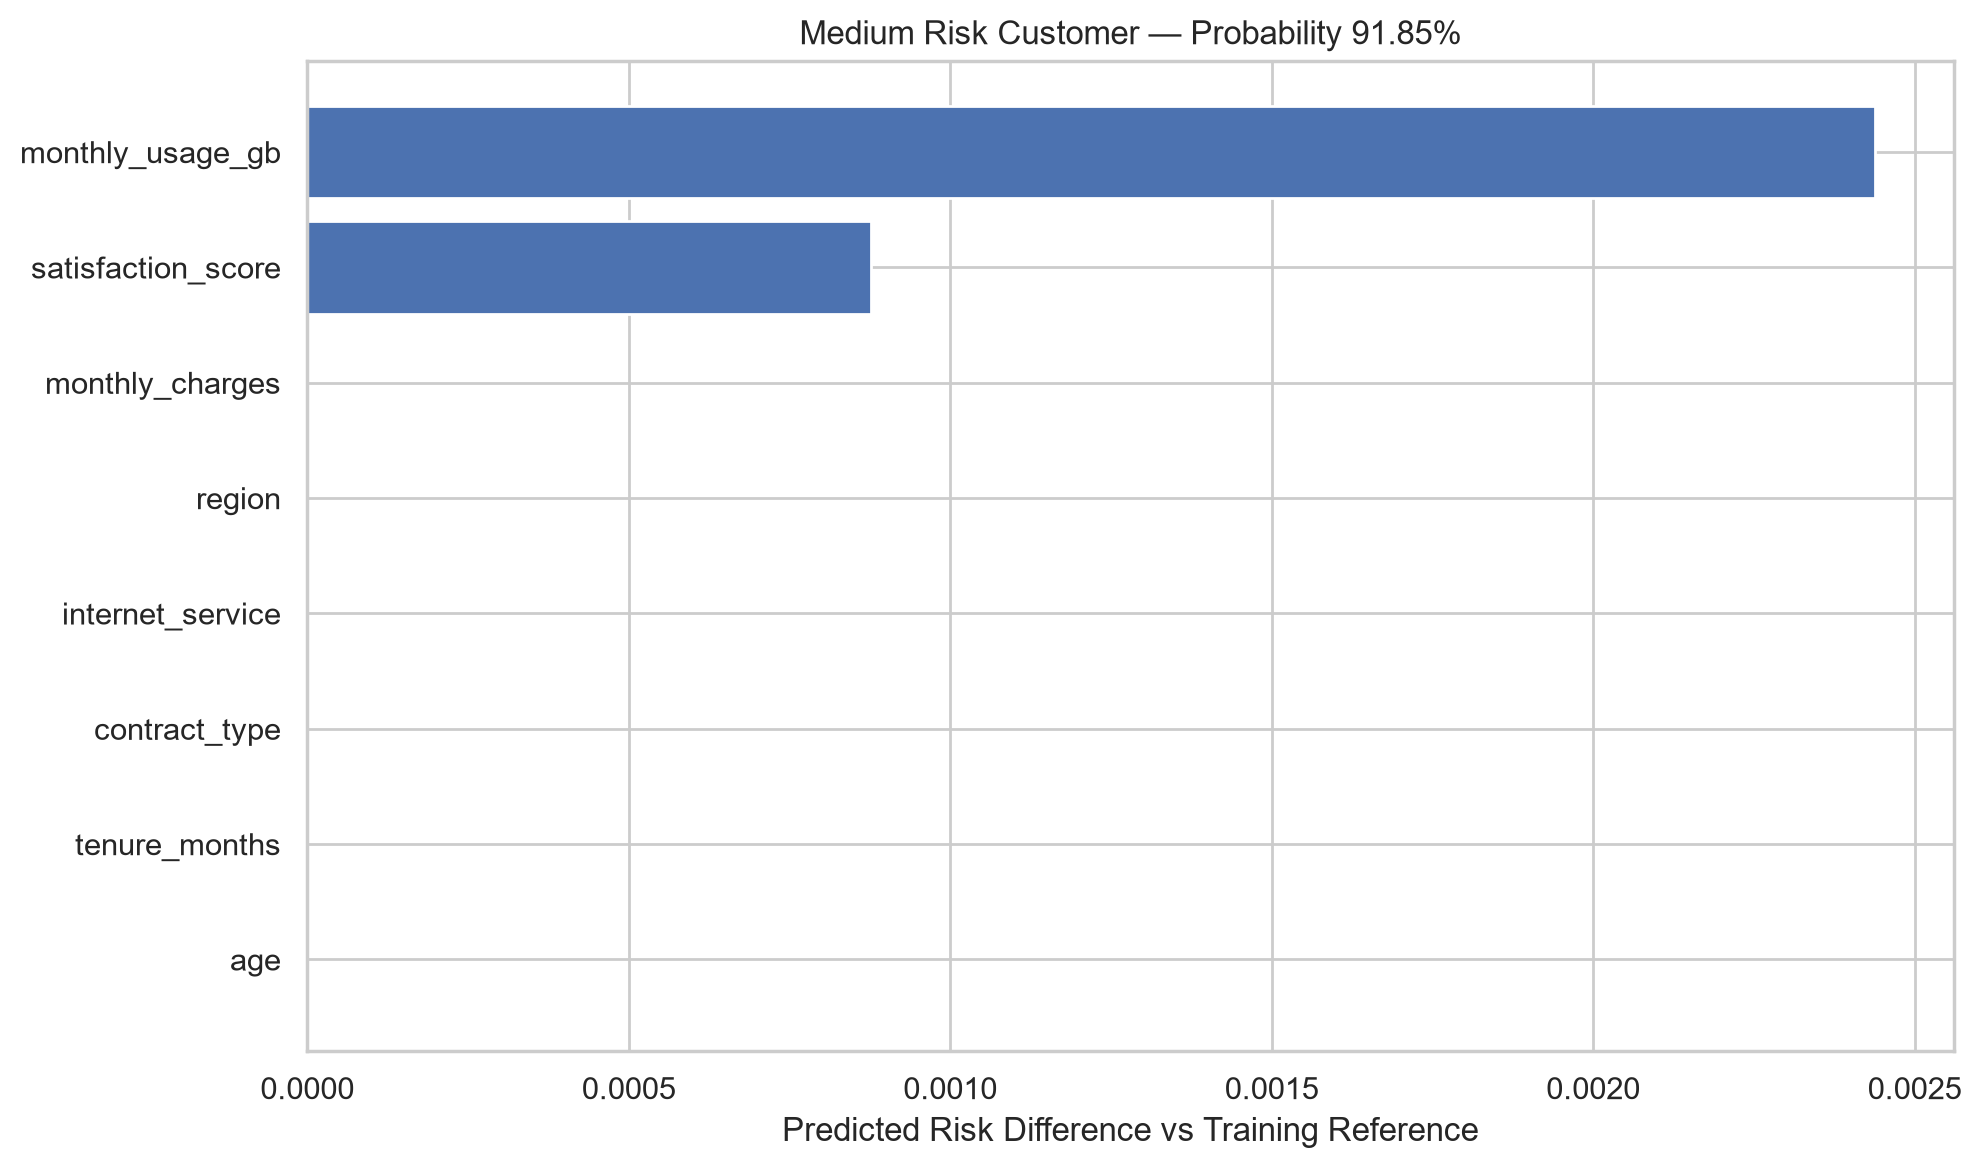


Figure: 15_high_risk_explanation.png


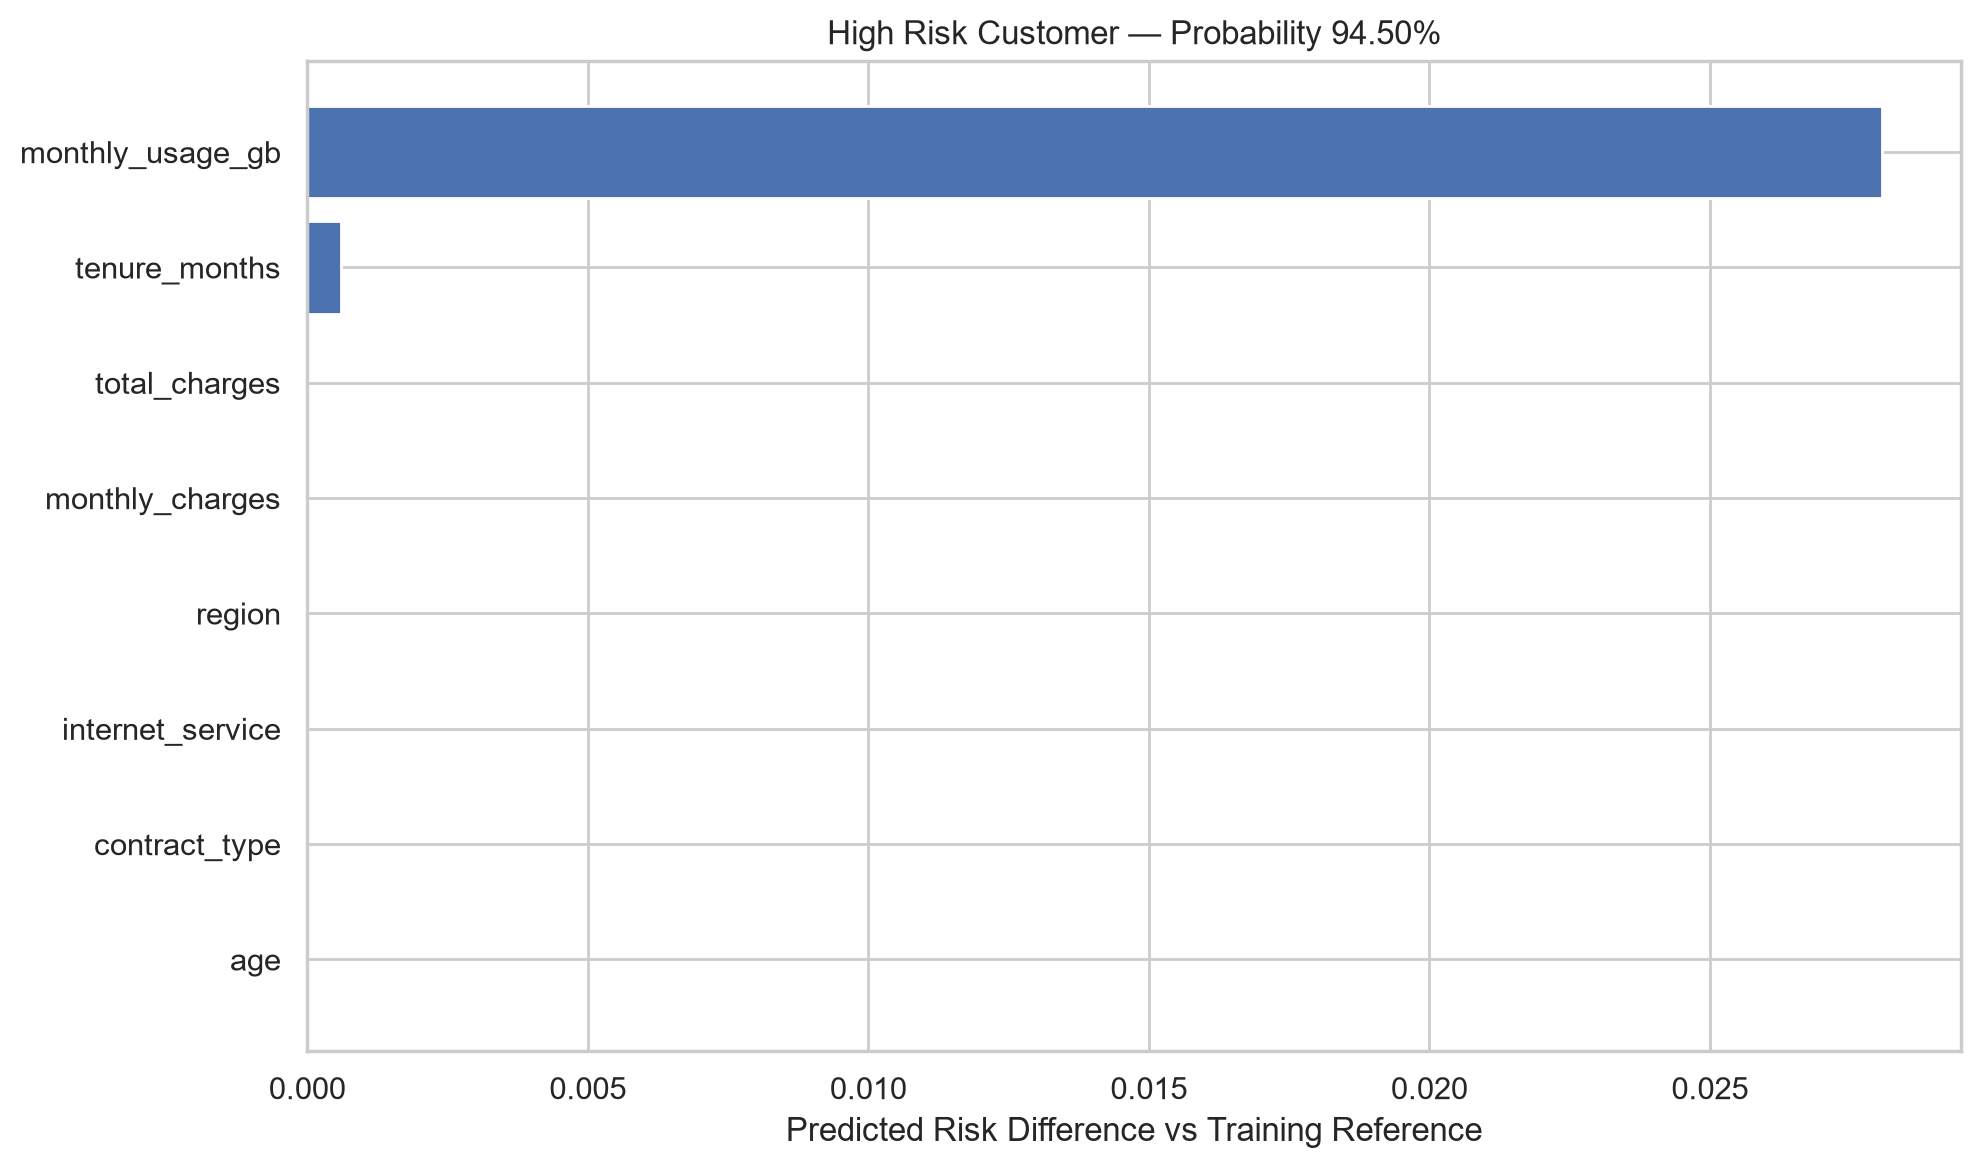

In [11]:
explanation_figures = [
    "14_global_feature_importance.png",
    "15_low_risk_explanation.png",
    "15_medium_risk_explanation.png",
    "15_high_risk_explanation.png",
]

for filename in explanation_figures:
    print("\nFigure:", filename)

    display(
        Image(
            filename=str(FIGURE_DIR / filename),
            width=750
        )
    )

## 9. Retention Intervention Simulation

The organization can contact only 20% of customers.

Customers are ranked by predicted churn probability.

The simulation compares:

- Model-based targeting
- Expected random targeting
- A hypothetical no-outreach baseline

Metrics include:

- Churners captured
- Precision at 20%
- Recall at 20%
- Lift at 20%
- Expected additional churners reached

### Hypothetical Financial Assumptions

- Contact cost: 5 monetary units
- Retained-customer value: 200 monetary units
- Intervention success probability: 15%

These values are illustrative assumptions.

The churn dataset does not provide actual intervention
outcomes or customer treatment effects.

In [12]:
from src.retention_analysis import main as retention_main

retention_main()

RETENTION_PATH = (
    ROOT / "reports" / "retention_simulation.json"
)

with open(RETENTION_PATH, encoding="utf-8") as file:
    retention_results = json.load(file)

print("Evaluation customers:",
      retention_results["evaluation_cohort"])

print("Contact capacity:",
      retention_results["contact_capacity"])

print("\nModel targeting results:")

display(
    pd.Series(
        retention_results["targeting"]
    ).to_frame("Value")
)

print("\nRandom targeting baseline:")

display(
    pd.Series(
        retention_results["random_baseline"]
    ).to_frame("Value")
)

print("\nHypothetical financial outcomes:")

display(
    pd.DataFrame(
        retention_results["financial_outcomes"]
    )
)

CUSTOMER RETENTION INTERVENTION SIMULATION
Total customers: 240
Contact capacity (20%): 48
Total actual churners: 207
Churn prevalence: 86.25%

MODEL TARGETING
Actual churners captured: 48
Precision @20%: 100.00%
Recall @20%: 23.19%
Lift @20%: 1.1594

RANDOM BASELINE
Expected churners captured: 41.40
Additional churners vs random expectation: 6.60

HYPOTHETICAL FINANCIAL SIMULATION
Model expected retained customers: 7.20
Model expected campaign cost: 240.00
Model expected net benefit: 1200.00
Random expected net benefit: 1002.00

Saved summary: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\reports\retention_simulation.json
Saved ranking: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\reports\retention_targeting.csv
Saved sensitivity: D:\Gamage Recruiters\task 5\ML_Individual_Task\end-to-end-customer-churn-prediction---retention-analysis-solution\reports

,Value
actual_churners_captured,48.000000
precision_at_20,1.000000
recall_at_20,0.231884
lift_at_20,1.159420



Random targeting baseline:


,Value
method,Expected uniform random sample
expected_churners_captured,41.4
expected_precision,0.8625
expected_recall,0.2



Hypothetical financial outcomes:


,model_targeting,random_targeting_expected,no_outreach_incremental_net_benefit,incremental_net_benefit_vs_random
contacts,48.00,48.000,0.0,198.0
churners_reached,48.00,41.400,0.0,198.0
success_rate,0.15,0.150,0.0,198.0
expected_retained_customers,7.20,6.210,0.0,198.0
campaign_cost,240.00,240.000,0.0,198.0
expected_benefit,1440.00,1242.000,0.0,198.0
expected_net_benefit,1200.00,1002.000,0.0,198.0
roi,5.00,4.175,0.0,198.0



Figure: 16_targeting_vs_random.png


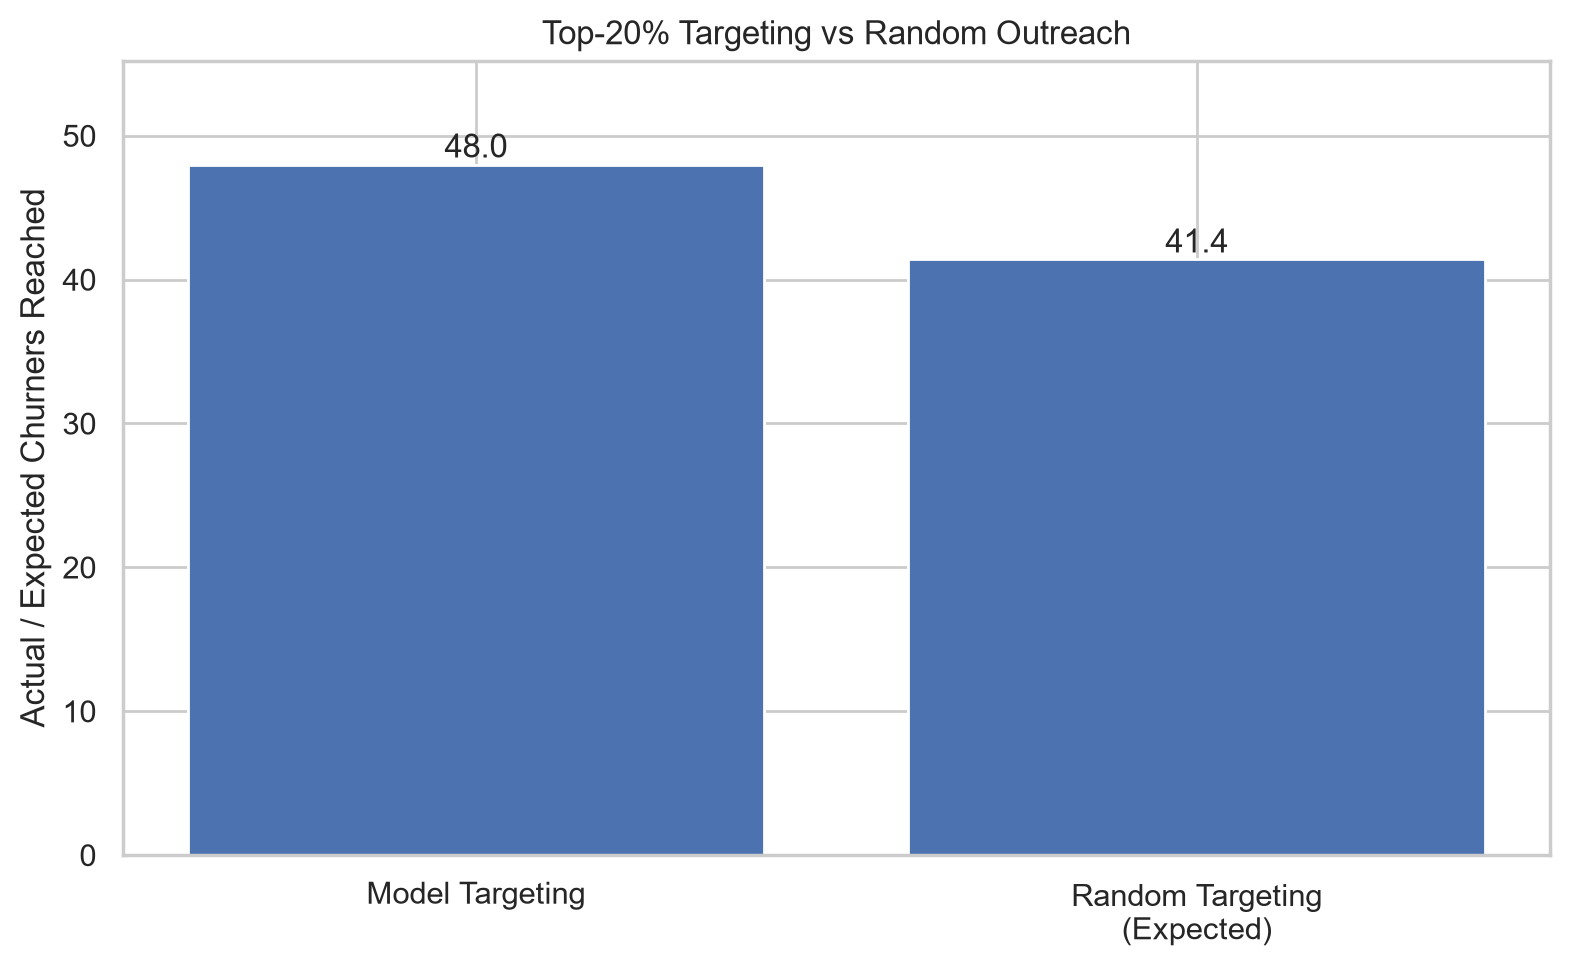


Figure: 17_cumulative_gains.png


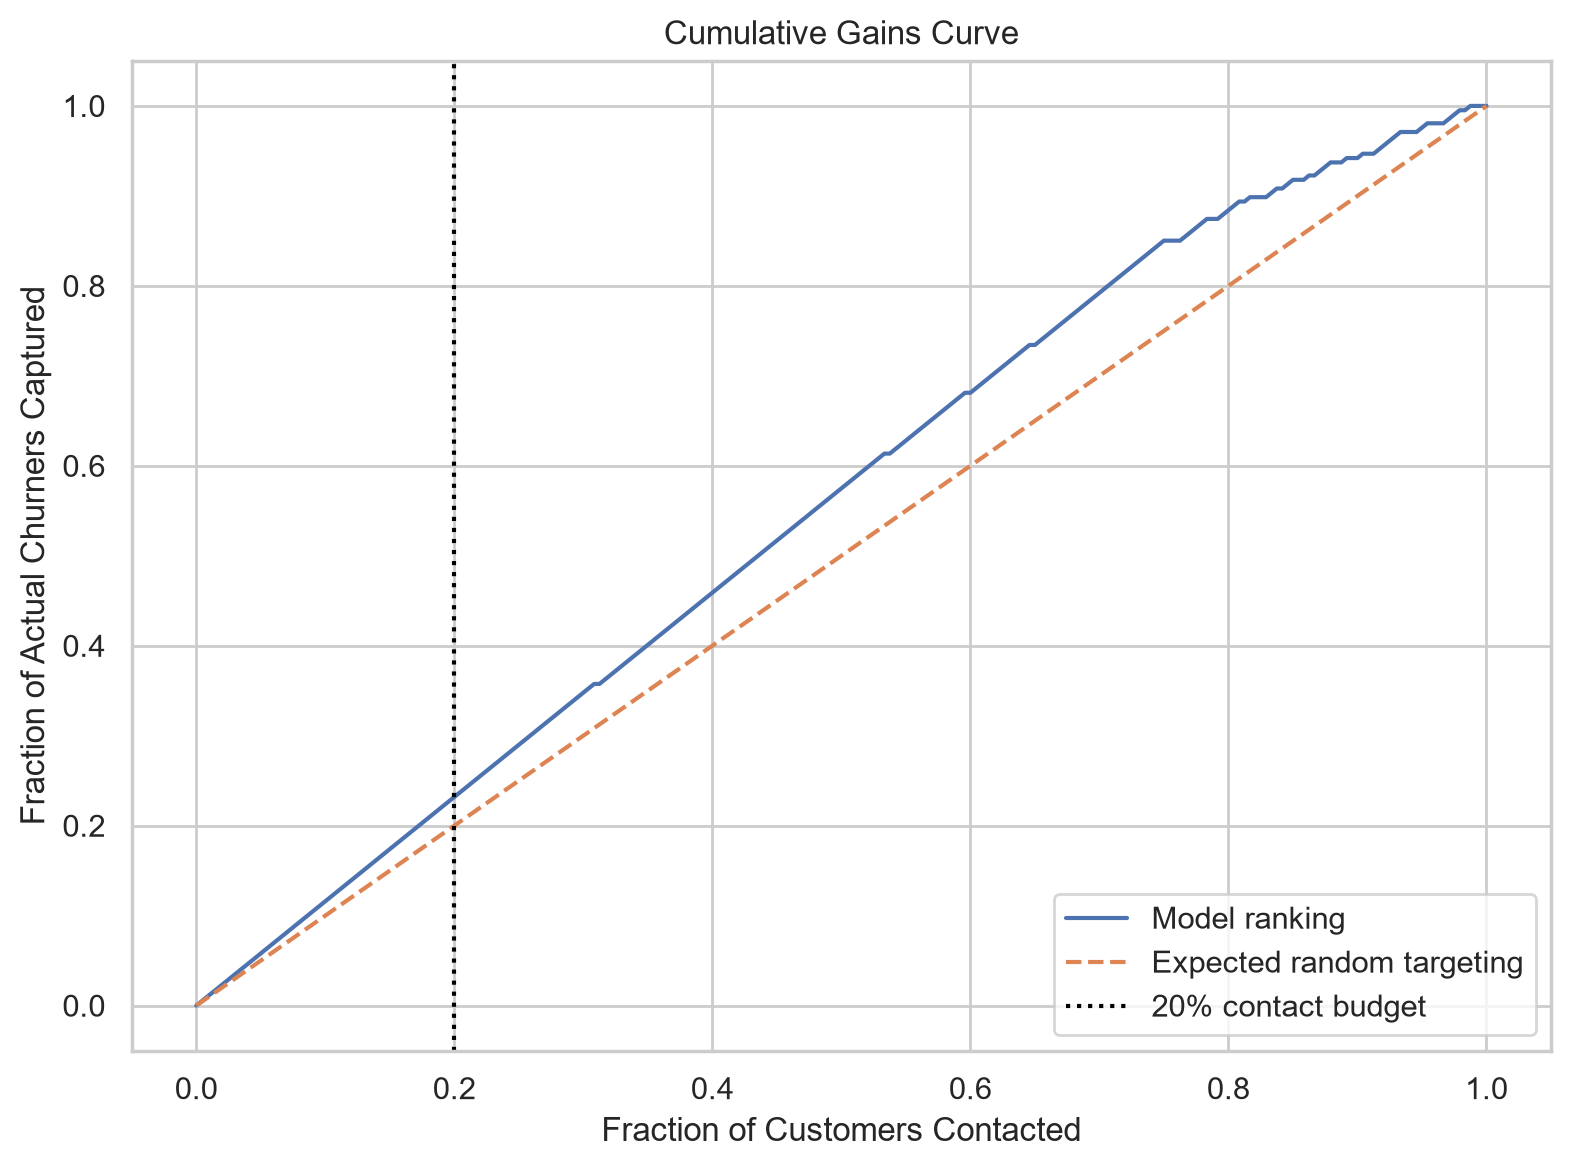


Figure: 18_financial_sensitivity.png


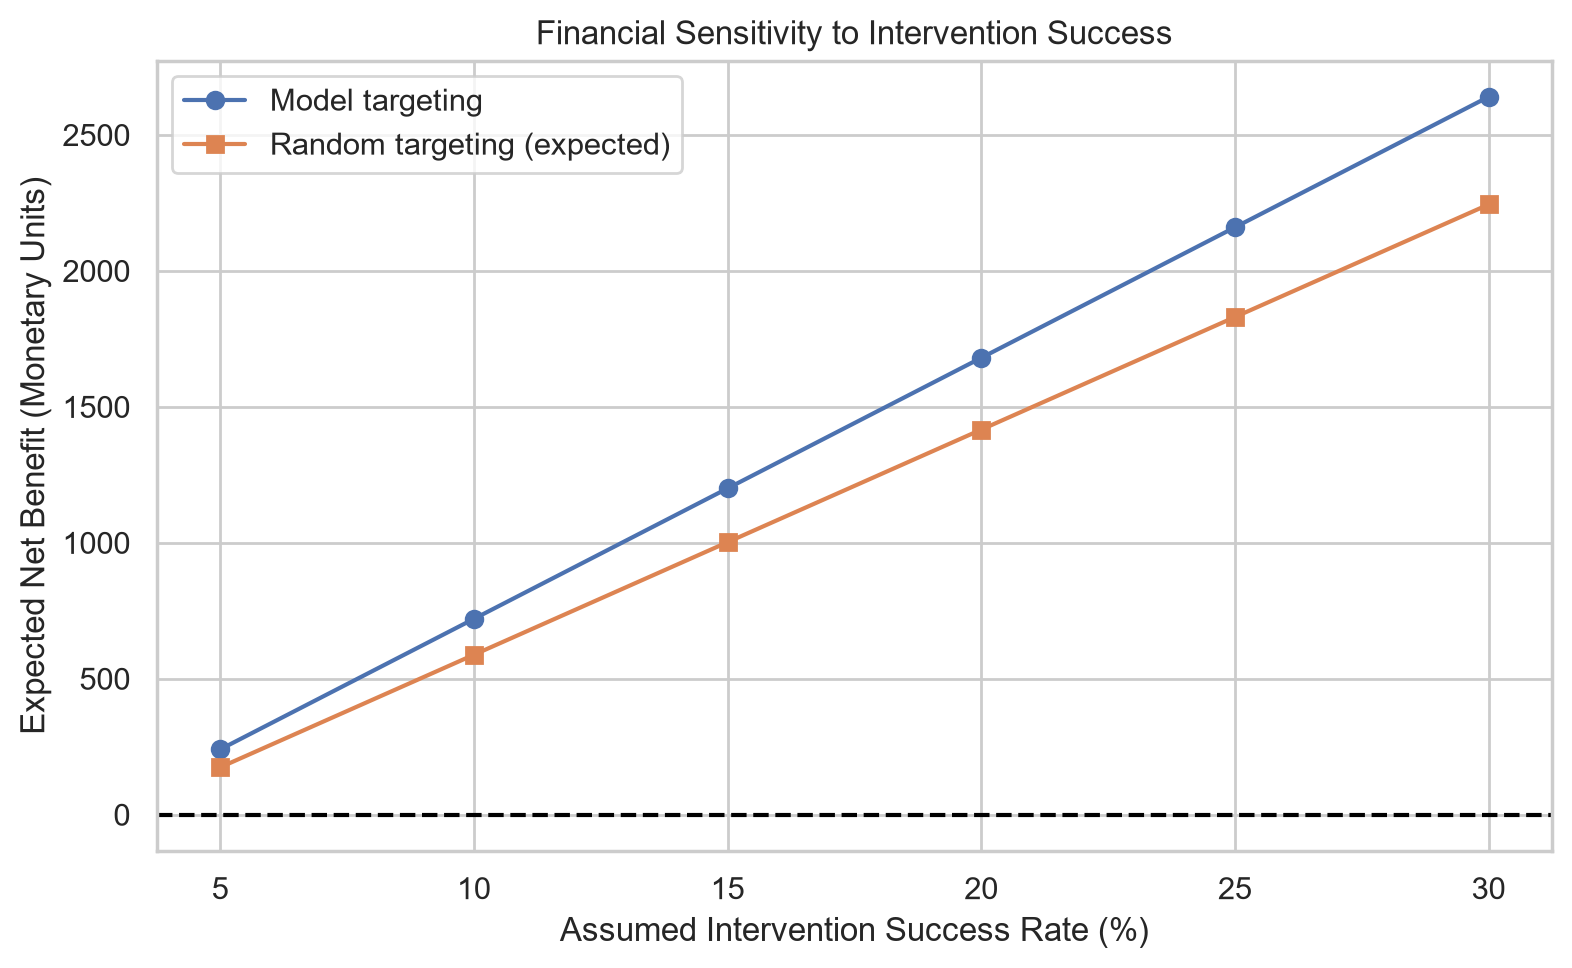

In [13]:
retention_figures = [
    "16_targeting_vs_random.png",
    "17_cumulative_gains.png",
    "18_financial_sensitivity.png",
]

for filename in retention_figures:
    print("\nFigure:", filename)

    display(
        Image(
            filename=str(FIGURE_DIR / filename),
            width=750
        )
    )

## 10. Business Recommendations

Based on the predictive analysis, the following
retention actions could be considered.

### 1. Usage-Based Customer Outreach

Monthly usage is an important predictive variable.

Investigate usage patterns and customer experience
before deciding which type of outreach is suitable.

### 2. Billing and Price Review

Review customers with potentially unfavorable
monthly charges or service-value perceptions.

Consider targeted billing assistance or
suitable plan recommendations.

### 3. Satisfaction and Complaint Management

Identify customers reporting dissatisfaction
or repeated complaints.

Prioritize service recovery and follow-up.

### 4. Contract-Based Retention Strategy

Study churn patterns across contract types.

Evaluate whether flexible plans, service upgrades
or renewal incentives improve customer retention.

### 5. Controlled Retention Experiment

Pilot interventions with randomized treatment
and control groups.

Measure actual incremental retention before
deploying expensive campaigns.

**Important:** Predictive associations do not
prove that these actions cause lower churn.

## 11. Limitations

1. The dataset has unusually high churn prevalence.
2. Only one final holdout dataset is available.
3. Model performance may change on future customers.
4. Training cross-validation was used for model selection.
5. Probability calibration was assessed, but not
   automatically corrected.
6. Explanations are predictive, not causal.
7. Financial results use hypothetical assumptions.
8. Actual intervention response is unknown.
9. Future data drift may reduce predictive performance.
10. Additional external validation is recommended.

## 12. Conclusion

This project develops an end-to-end customer churn
prediction and retention analysis solution.

The workflow includes:

- Reproducible data preparation
- Exploratory data analysis
- Leakage-aware feature engineering
- Three classification algorithms
- Cross-validation and hyperparameter tuning
- Comprehensive model evaluation
- Explainable predictions
- Top-20% retention targeting
- Hypothetical financial simulation

The final Gradient Boosting pipeline can rank
customers according to predicted churn probability.

The business can use this ranking to prioritize
limited outreach resources.

Actual intervention effectiveness should be
validated through controlled experiments.

All generated artifacts, charts, model outputs
and documentation are maintained in the
GitHub project repository.